# 🔭 GRB Photometry Pipeline
**Author:** [Your Name]
**Target:** GRB 241002A
**Instrument:** [Your Telescope/Camera]

---
## Pipeline Overview
```
CELL 1  → Imports
CELL 2  → Configuration & Paths
CELL 3  → Output Folder Setup
CELL 4  → Core Helper Functions
CELL 5  → Step 0.5: Local Plate Solving
CELL 6  → Step 1-2: FWHM & Background Estimation
CELL 7  → Step 3-4: Convolution & Source Detection
CELL 8  → Step 5: Morphological Filtering & Catalog
CELL 9  → Step 6: DAOStarFinder + Shape Filtering
CELL 10 → Step 6: Multi-Aperture Photometry
CELL 11 → Step 7: Astrometry & GRB Verdict
CELL 12 → Step 8: Pan-STARRS Zero-Point Calibration
CELL 13 → Step 8.5: Calibration Diagnostics
CELL 14 → Step 9: Forced Photometry & Upper Limit
CELL 15 → Save All Outputs (Plots + FITS + Catalogs)
```
---
### 💡 Future Extension Points
- **Photo-stacking:** See `CELL 4` for `stack_images()` function stub
- **Cosmic Ray Rejection:** `astroscrappy` is imported; add a call in CELL 5
- **Different Filters (B/V/I):** Change `FILTER_BAND` and `VIZIER_MAG_COL` in CELL 2
- **Different Catalogs:** Swap `VIZIER_CATALOG_ID` in CELL 2 (e.g., SDSS, APASS)
- **New Object Type:** Change `TARGET_RA`, `TARGET_DEC`, and `TARGET_NAME` in CELL 2

In [1]:
# ==========================================================
# EXTRACT DATE AND JULIAN DAY FROM FITS HEADER
# ==========================================================
from astropy.io import fits
from astropy.time import Time

# Define the path to your FITS file here
sample_fits_file = "fbGRB200412B_I_2148x2148_18022.fits" # Update with actual file if needed

try:
    with fits.open(sample_fits_file) as hdul:
        header = hdul[0].header
        
        # Look for common date keywords
        date_obs = header.get('DATE-OBS', None)
        
        if date_obs:
            # Some FITS headers have 'T' in DATE-OBS, some have space. Time() handles most standard ISO formats.
            t = Time(date_obs, format='isot', scale='utc')
            
            print(f"Observation Date (UTC): {t.iso}")
            print(f"Julian Date (JD): {t.jd:.6f}")
            
            # Optional: Calculate IST (UTC + 5:30)
            import astropy.units as u
            from astropy.time import TimeDelta
            t_ist = t + TimeDelta(5.5 * u.hour)
            print(f"Observation Date (IST): {t_ist.iso}")
        else:
            print("DATE-OBS keyword not found in the header.")
except Exception as e:
    print(f"Error reading header from {sample_fits_file}: {e}")


Error reading header from fbGRB200412B_I_2148x2148_18022.fits: [Errno 2] No such file or directory: 'fbGRB200412B_I_2148x2148_18022.fits'


### 🔍 Source Morphology Filters (The "Bouncer" Rules)

**1. Roundness (The Oval Filter)**
Measures how circular a source is (perfect = `0.0`).
* **`roundness1`**: Detects vertical/horizontal stretching.
* **`roundness2`**: Detects diagonal stretching.
* **Tuning:** If stars are slightly trailed or elongated, widen the default `(-0.5, 0.5)` bounds. 
  * *Suggested Change:* `ROUNDNESS1_RANGE = (-0.8, 0.8)` and `ROUNDNESS2_RANGE = (-0.8, 0.8)`

**2. Sharpness (The Focus Filter)**
Measures how tightly peaked the light profile is (typical stars = `0.5` to `0.8`).
* **Lower Bound:** Rejects blurry, diffuse objects like galaxies or smeared noise. (Lower to catch fainter/blurrier stars).
* **Upper Bound:** Rejects artificially sharp artifacts like cosmic rays or hot pixels. (Raise if tight, bright stars are being rejected).
* **Tuning:** To catch a wider variety of valid stars without letting in too much junk, relax the default `(0.2, 1.0)` bounds.
  * *Suggested Change:* `SHARPNESS_RANGE = (0.1, 1.5)`

### 📚 Catalog Selection Guide for Photometric Calibration

To get the most accurate zero point, you must select the catalog that best matches your target filter. 

| Target Filter | `CALIBRATION_SYSTEM` | `DIRECT_VEGA_CATALOG` | VizieR ID |
|:---:|:---|:---|:---|
| **Bessel U** | *(Requires SDSS)* | *(Not in APASS/PS1)* | `V/147/sdss12` |
| **Bessel B** | `'DIRECT_VEGA'` | `'APASS'` | `II/336/apass9` |
| **Bessel V** | `'DIRECT_VEGA'` | `'APASS'` | `II/336/apass9` |
| **Bessel R** | `'Pan-STARRS'` | *(Ignored)* | `II/349/ps1` |
| **Bessel I** | `'Pan-STARRS'` | *(Ignored)* | `II/349/ps1` |

**Quick Rules:**
*   **U Band**: Neither **APASS** nor **Pan-STARRS** provide UV data. To calibrate $U$-band, you must query **SDSS** (if your target is in its footprint) and apply transformations, or rely on targeted Landolt field observations(The Landolt catalog (`II/183A`) does not provide direct U magnitudes. Instead, it provides a `U-B` color index. You can mathematically derive the U magnitude by combining it with the B-band using the formula: **U = B + (U-B)**.).
* **B & V Bands:** Always prefer **APASS**. It provides native Johnson-Cousins magnitudes, meaning no mathematical transformations are needed. *(Fallback: If your V-band image is very deep and APASS stars are too faint, switch to Pan-STARRS).*
* **R & I Bands:** Always use **Pan-STARRS**. APASS does not provide native Bessel R or I. Pan-STARRS is deeper, and the pipeline will automatically apply the highly-accurate Lupton (2005) color transformations to synthesize R and I.
* **Landolt (`II/183A/table2`):** Only use this setting if you specifically observed a dedicated Landolt Standard Field (e.g., PG 1323) to calculate atmospheric extinction. Do not use for general in-field GRB calibration.

In [2]:
# CELL 1: ALL IMPORTS
# ============================================================
# ============================================================

# --- Standard Library ---
import os
import glob
import subprocess
import warnings

# --- Numerical & Table ---
import numpy as np
from astropy.table import Table, hstack

# --- FITS & WCS ---
from astropy.io import fits
from astropy.wcs import WCS
from astropy.nddata import Cutout2D
from astropy.utils.exceptions import AstropyUserWarning

# --- Coordinates & Units ---
from astropy.coordinates import SkyCoord
import astropy.units as u

# --- Statistics ---
from astropy.stats import sigma_clipped_stats, SigmaClip, sigma_clip

# --- Modeling & Fitting ---
from astropy.modeling import models, fitting

# --- Visualization ---
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from astropy.visualization import ZScaleInterval, LinearStretch
from astropy.visualization.mpl_normalize import ImageNormalize

# --- Background Estimation ---
from photutils.background import Background2D, SExtractorBackground

# --- Source Detection ---
from photutils.detection import DAOStarFinder, find_peaks
from photutils.segmentation import (
    detect_threshold, detect_sources,
    SourceFinder, SourceCatalog
)

# --- Aperture Photometry ---
from photutils.aperture import (
    CircularAperture, CircularAnnulus,
    aperture_photometry, ApertureStats
)

# --- Utilities ---
from photutils.utils import circular_footprint, calc_total_error
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel

# --- Catalog Queries ---
from astroquery.vizier import Vizier
# from astroquery.astrometry_net import AstrometryNet  # Uncomment for online plate solving

# --- Cosmic Ray Rejection ---
import astroscrappy

# --- Image Alignment (for stacking) ---
import astroalign as aa

# --- PSF Photometry ---
from photutils.psf import CircularGaussianPRF, PSFPhotometry, SourceGrouper
from photutils.background import LocalBackground, MMMBackground

from astroquery.astrometry_net import AstrometryNet

print("✅ All imports loaded successfully.")

# --- Photometry Recentering ---
from photutils.centroids import centroid_2dg
from astropy.nddata import Cutout2D


✅ All imports loaded successfully.


In [3]:
# ==========================================================
# TRIGGER TIME CALCULATION (UT to IST and Julian Date)
# ==========================================================
from astropy.time import Time, TimeDelta
import astropy.units as u

# The exact UT trigger time of the GRB (Format: YYYY-MM-DD HH:MM:SS.ss)
# For 09:08:40.71 UT on 12 April 2020:
trigger_time_str = '2020-04-12 09:08:40.71'

# Create an Astropy Time object
t_trigger_ut = Time(trigger_time_str, format='iso', scale='utc')

# IST is UT + 5 hours and 30 minutes
ist_offset = TimeDelta(5.5 * u.hour)
t_trigger_ist = t_trigger_ut + ist_offset

# Extract the Julian Date (JD)
GRB_T0_JD = t_trigger_ut.jd

print(f"GRB Trigger (UT) : {t_trigger_ut.iso}")
print(f"GRB Trigger (IST): {t_trigger_ist.iso}")
print(f"GRB Trigger (JD) : {GRB_T0_JD:.6f}")

GRB Trigger (UT) : 2020-04-12 09:08:40.710
GRB Trigger (IST): 2020-04-12 14:38:40.710
GRB Trigger (JD) : 2458951.881027


In [4]:
# ==========================================================
# GRB CORDINATE CALCULATION (Hexadecimal to Degree)
# ==========================================================
from astropy.coordinates import SkyCoord
import astropy.units as u

# You can pass the coordinate string almost exactly as it is written
coord_string = "18h33m15.21s +62d31m57.1s"

# Parse the coordinates using astropy
c = SkyCoord(coord_string, frame='icrs')

# Extract the decimal degrees
ra_decimal = c.ra.deg
dec_decimal = c.dec.deg

print(f"RA (Decimal Degrees): {ra_decimal:.6f}°")
print(f"Dec (Decimal Degrees): {dec_decimal:.6f}°")

RA (Decimal Degrees): 278.313375°
Dec (Decimal Degrees): 62.532528°


In [5]:
# ==========================================================
# Print the list of all exact column names in APASS DR9 catalog structure
# ==========================================================
from astroquery.vizier import Vizier

# Query the APASS DR9 catalog structure
apass_catalogs = Vizier.get_catalogs('II/183A/table2')

# APASS only has one main data table, which is index [0]
apass_table = apass_catalogs[0]

# Print the list of all exact column names
print("Available APASS Columns:")
print(apass_table.colnames)

Available APASS Columns:
['RAJ2000', 'DEJ2000', 'Vmag', 'e_Vmag', 'B-V', 'e_B-V', 'U-B', 'e_U-B', 'V-R', 'e_V-R', 'R-I', 'e_R-I', 'V-I', 'e_V-I', 'SimbadName']


In [6]:
# ============================================================
# CELL 2: CONFIGURATION & PARAMETERS
# ============================================================
# 🔧 ALL tunable knobs live here. No need to dig into functions.
# ----------------------------------------------------------
# 2A. PIPELINE MODE & FILE PATHS
# ----------------------------------------------------------
# Toggle this between 'single','stack' or 'batch'
RUN_MODE = 'stack'  # 'single', 'stack', or 'batch'
PLATE_SOLVE_MODE = 'online'               # 'local', 'online', 'copy', or 'external'
WCS_REFERENCE_SOLVED_PATH = "/home/void/GRB_DATA/GRB200412_ASTROROB/2020_04_16/pipeline_output/fits_solved/online_solved_aaGRB_R_7.fits"   # Used if mode is 'copy'
EXTERNAL_SOLVED_FILE_PATH = "/home/void/GRB_DATA/GRB200412_ASTROROB/2020_04_23/pipeline_output/fits_solved/Astrometry_MASTER_STACKED_fbGRB200412B_R.fits"  # Used if mode is 'external'
# Define your files so you never have to retype them
SINGLE_FRAME_FILE  = "aaGRB_R_10.fits"
BATCH_PATTERN      = "aaGRB_R*.fits"
STACK_PATTERN      = "aaGRB_R*.fits"
STACKED_FILENAME   = "MASTER_STACKED_aaGRB_R.fits"
ASTROMETRY_CFG     = "/home/void/astrometry_data/local.cfg"  
OUTPUT_BASE_DIR    = "./pipeline_output"
# ----------------------------------------------------------
# 2B. TARGET COORDINATES (GRB / Transient)
# ----------------------------------------------------------
TARGET_NAME         = "GRB200412"      # Used in plot titles and filenames
GRB_T0_JD           = 2458951.881027          # GRB Trigger Time in Julian Days
TARGET_RA           = 278.313375           # degrees (J2000)
TARGET_DEC          = +62.532528           # degrees (J2000)
MATCH_RADIUS_ARCSEC = 3.0               # Arcsec threshold for detection verdict
RECENTER_RADIUS_PIX = 8.0               # Max pixels to shift aperture to nearest peak
# ----------------------------------------------------------
# 2C. DETECTION & PHOTOMETRY PARAMETERS
# ----------------------------------------------------------
DETECT_SIGMA        = 4.0              # DAOStarFinder detection threshold (x sigma)
EDGE_BUFFER_PIXELS  = 100              # Ignore sources within N pixels of image edge
FWHM_PEAK_SIGMA     = 15.0             # Sigma threshold for FWHM star selection
BG_BOX_SIZE         = (25, 25)         # 2D background estimation box size
BG_FILTER_SIZE      = (3, 3)           # 2D background filter size
SATURATION_LIMIT    = 55000            # Fallback saturation level (ADU), overridden by header
EFFECTIVE_GAIN      = 5.0              # e-/ADU (change based on your instrument)
READ_NOISE          = 10.0              # e- (change based on your instrument)
# Aperture multipliers (multiples of FWHM) for Curve of Growth
APERTURE_MULTIPLIERS = [1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
OPTIMAL_APERTURE     = 1.5             # Which multiplier to use for final magnitudes
# Annulus for local background estimation
ANNULUS_INNER_MULT  = 2.0              # r_in = N * FWHM
ANNULUS_OUTER_MULT  = 4.0              # r_out = N * FWHM
# Upper limit sigma (e.g., 3-sigma = standard in GRB papers)
UPPER_LIMIT_SIGMA   = 3.0
# ----------------------------------------------------------
# 2D. SOURCE MORPHOLOGY FILTERS (The "Bouncer" rules)
# ----------------------------------------------------------
ROUNDNESS1_RANGE    = (-0.6, 0.6)      # DAOStarFinder roundness1 filter.  
ROUNDNESS2_RANGE    = (-0.6, 0.6)      # DAOStarFinder roundness2 filter
SHARPNESS_RANGE     = (0.2, 1.0)       # DAOStarFinder sharpness filter
# ----------------------------------------------------------
# 2E. CATALOG CALIBRATION CONFIGURATION
# ----------------------------------------------------------
CALIBRATION_SYSTEM  = 'Pan-STARRS'    # Options: 'Pan-STARRS' or 'DIRECT_VEGA'
DIRECT_VEGA_CATALOG = 'APASS'          # Options: 'APASS', 'Landolt', or 'Gaia'
FILTER_BAND         = 'R'              # Target observing filter
# --- DYNAMIC QUALITY CONSTRAINTS ---
# Group 1: Dense, Deep, High-Precision Catalogs
if CALIBRATION_SYSTEM == 'Pan-STARRS' or DIRECT_VEGA_CATALOG == 'Gaia':
    QUERY_RADIUS_ARCMIN = 8                
    REF_MAG_BRIGHT      = 14.0
    REF_MAG_FAINT       = 16.5
    REF_MAG_ERR_MAX     = 0.05
    ZP_MATCH_RADIUS_AS  = 3.5             
# Group 2: Sparse, Shallow, or Classical Catalogs
elif CALIBRATION_SYSTEM == 'DIRECT_VEGA' and DIRECT_VEGA_CATALOG in ['APASS', 'Landolt']:
    QUERY_RADIUS_ARCMIN = 15                
    REF_MAG_BRIGHT      = 12.0          
    REF_MAG_FAINT       = 17.5
    REF_MAG_ERR_MAX     = 0.10
    ZP_MATCH_RADIUS_AS  = 5.0             
# Global settings for all catalogs
VIZIER_ROW_LIMIT    = 5000             
ZP_MIN_STARS        = 5
# ----------------------------------------------------------
# 2F. ADVANCED PSF PHOTOMETRY PARAMETERS
# ----------------------------------------------------------
PSF_FIT_SHAPE             = (5, 5)     # Size of the fitting box (should cover the high SNR core)
PSF_GROUPER_MIN_SEP_MULT  = 2.0        # Multiplier of FWHM to group blended stars (the "peanut" rule)
PSF_MATCH_RADIUS_PIXELS   = 5.0        # Pixel radius to match the final PSF model to the GRB coordinate
# ----------------------------------------------------------
# 2G. DIAGNOSTIC PLOT PARAMETERS (Curve of Growth)
# ----------------------------------------------------------
DIAG_ZOOM_PIXELS      = 20               # How many pixels to show around the GRB 
DIAG_PLOT_MULTIPLIERS = [1.25, 1.5, 2.0, 2.5] # Which apertures to draw as visual circles
DIAG_CONTAM_ZONE      = (2.0, 3.0)       # X-axis range to highlight as "Contaminated"
print("✅ Configuration loaded.")
print(f"   Mode   : {RUN_MODE.upper()}")
print(f"   Target : {TARGET_NAME} @ RA={TARGET_RA}, Dec={TARGET_DEC}")
print(f"   Filter : {FILTER_BAND}-band")


✅ Configuration loaded.
   Mode   : STACK
   Target : GRB200412 @ RA=278.313375, Dec=62.532528
   Filter : R-band


In [7]:
# CELL 3: OUTPUT FOLDER STRUCTURE
# ============================================================
# ============================================================

# Outputs are organised into subdirectories by type.
import os

def setup_output_dirs(input_name, mode):
    global DIRS
    base_name = os.path.splitext(os.path.basename(input_name))[0]
    base_name = base_name.replace('*', 'all')
    out_dir = os.path.join(OUTPUT_BASE_DIR, f"{base_name}_{mode}_{CALIBRATION_SYSTEM}")
    DIRS = {
        "plots_detection"  : os.path.join(out_dir, "plots", "detection"),
        "plots_calibration": os.path.join(out_dir, "plots", "calibration"),
        "plots_target"     : os.path.join(out_dir, "plots", "target"),
        "fits_solved"      : os.path.join(OUTPUT_BASE_DIR, "fits_solved"), # Unified folder for easier reference
        "fits_reduced"     : os.path.join(out_dir, "fits", "reduced"),
        "fits_stacked"     : os.path.join(out_dir, "fits", "stacked"),
        "catalogs"         : os.path.join(out_dir, "catalogs"),
        "logs"             : os.path.join(out_dir, "logs"),
    }
    for name, path in DIRS.items():
        os.makedirs(path, exist_ok=True)
    return out_dir

if RUN_MODE == 'single':
    active_out_dir = setup_output_dirs(SINGLE_FRAME_FILE, RUN_MODE)
elif RUN_MODE == 'stack':
    active_out_dir = setup_output_dirs(STACKED_FILENAME, RUN_MODE)
elif RUN_MODE == 'batch':
    active_out_dir = setup_output_dirs(BATCH_PATTERN, RUN_MODE)
else:
    active_out_dir = setup_output_dirs("unknown", RUN_MODE)

print("✅ Output folder structure created:")
print(f"   Base Directory : {active_out_dir}")
for name, path in DIRS.items():
    print(f"   {name:<22} → {path}")


✅ Output folder structure created:
   Base Directory : ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS
   plots_detection        → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/detection
   plots_calibration      → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/calibration
   plots_target           → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/target
   fits_solved            → ./pipeline_output/fits_solved
   fits_reduced           → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/fits/reduced
   fits_stacked           → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/fits/stacked
   catalogs               → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/catalogs
   logs                   → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/logs


In [8]:
# CELL 4: FUNCTION DEFINITIONS
# ============================================================
# ============================================================
# All reusable functions are defined here so they can be
# called cleanly in any later cell or from external scripts.

# ==========================================================
# BACKEND: CATALOG COLUMN MAPPING (Do not edit)
# ==========================================================
def get_catalog_columns(calib_system, vega_catalog, filter_band):
    """
    Returns the exact VizieR ID, columns list, magnitude column, 
    and error column based on the selected catalog and filter.
    """
    if calib_system == 'Pan-STARRS':
        return 'II/349/ps1', ['RAJ2000', 'DEJ2000', 'gmag', 'e_gmag', 'rmag', 'e_rmag', 'imag', 'e_imag'], None, None
        
    elif calib_system == 'DIRECT_VEGA':
        
        if vega_catalog == 'APASS':
            cat_id = 'II/336/apass9'
            coord_cols = ['RAJ2000', 'DEJ2000']
            valid_cols = {
                'V': ('Vmag', 'e_Vmag'),
                'B': ('Bmag', 'e_Bmag'),
                'g': ("g'mag", "e_g'mag"),
                'r': ("r'mag", "e_r'mag"),
                'i': ("i'mag", "e_i'mag")
            }
            
        elif vega_catalog == 'Landolt':
            cat_id = 'II/183A/table2'
            coord_cols = ['RAJ2000', 'DEJ2000']
            valid_cols = {
                'V': ('Vmag', 'e_Vmag')
            }
            
        elif vega_catalog == 'Gaia':
            cat_id = 'I/355/gaiadr3'
            coord_cols = ['RA_ICRS', 'DE_ICRS']
            valid_cols = {
                'G':  ('Gmag', 'e_Gmag'), 
                'BP': ('BPmag', 'e_BPmag'),
                'RP': ('RPmag', 'e_RPmag')
            }
            
        else:
            raise ValueError(f"Unknown DIRECT_VEGA_CATALOG: {vega_catalog}")

        if filter_band not in valid_cols:
            raise ValueError(
                f"\n[CRITICAL ERROR] The {vega_catalog} catalog does not have a direct "
                f"column for the '{filter_band}' filter.\n"
                f"Available direct filters for {vega_catalog} are: {list(valid_cols.keys())}"
            )
            
        mag_col, err_col = valid_cols[filter_band]
        cols_to_download = coord_cols + [mag_col, err_col]
        
        return cat_id, cols_to_download, mag_col, err_col

# Initialize the global VizieR variables using the function
VIZIER_CATALOG_ID, VIZIER_COLUMNS, VIZIER_MAG_COL, VIZIER_ERR_COL = get_catalog_columns(
    CALIBRATION_SYSTEM, DIRECT_VEGA_CATALOG, FILTER_BAND
)


# ------------------------------------------------------------
# F1: PLATE SOLVING
# ------------------------------------------------------------
def run_local_plate_solve(image_file, config_path, target_ra, target_dec, search_radius=2.0):
    """
    Runs astrometry.net solve-field locally.
    """
    # --- Caching Check ---
    dest = os.path.join(DIRS["fits_solved"], "solved_" + os.path.basename(image_file))
    if os.path.exists(dest):
        print(f"[Plate Solve] ♻️ Found cached solved file: {dest}")
        data, header = fits.getdata(dest, header=True)
        wcs = WCS(header, naxis=2)
        return dest, data, header, wcs
    
    print(f"[Plate Solve] Running solve-field on {image_file}...")
    
    result = subprocess.run([
        "solve-field", image_file, 
        "--config", config_path,
        "--ra", str(target_ra),        
        "--dec", str(target_dec),
        "--radius", str(search_radius),  # Shrunk from 5.0 to 2.0 to massively speed up math
        "--scale-units", "arcsecperpix", 
        "--scale-low", "0.50",           # Adjust these if you got exact numbers from the web
        "--scale-high", "1.00",      
        "--downsample", "2",           
        "--cpulimit", "300",             # Override default timeouts: Give it up to 5 minutes
        "--no-plots",                  
        "--overwrite"
    ], capture_output=True, text=True)
    
    base_name, _ = os.path.splitext(image_file)
    solved_file = base_name + ".new"
    
    if os.path.exists(solved_file):
        dest = os.path.join(DIRS["fits_solved"], "solved_" + os.path.basename(image_file))
        os.rename(solved_file, dest)
        data, header = fits.getdata(dest, header=True)
        wcs = WCS(header, naxis=2)
        print(f"[Plate Solve] ✅ Success → {dest}")
        return dest, data, header, wcs
    else:
        print("[Plate Solve] ❌ Local Plate Solving Failed.")
        print("\n" + "="*50)
        print("   PROCESS OUTPUT (STDOUT)")
        print("="*50)
        print(result.stdout[-1500:]) 
        return None, None, None, None
# [ignoring loop detection]
# ------------------------------------------------------------
# F1.5: ONLINE PLATE SOLVING (ASTROMETRY.NET)
# ------------------------------------------------------------
def run_online_plate_solve(image_file, target_ra=TARGET_RA, target_dec=TARGET_DEC, search_radius=5.0):
    """
    Uploads an image to the online Astrometry.net API.
    """
    # --- Caching Check ---
    dest = os.path.join(DIRS["fits_solved"], "online_solved_" + os.path.basename(image_file))
    if os.path.exists(dest):
        print(f"[Astrometry.net] ♻️ Found cached solved file: {dest}")
        data, wcs_header = fits.getdata(dest, header=True)
        wcs = WCS(wcs_header)
        return dest, data, wcs_header, wcs
    
    print(f"[Astrometry.net] Initializing connection and setting API key...")
    ast = AstrometryNet()
    ast.api_key = 'amotqpkwnlpdlyqj'
    
    solve_kwargs = {
        "force_image_upload": True,
        "scale_units": "arcsecperpix",
        "scale_lower": 0.1,
        "scale_upper": 2.0
    }
    
    if target_ra is not None and target_dec is not None:
        solve_kwargs["center_ra"] = target_ra
        solve_kwargs["center_dec"] = target_dec
        solve_kwargs["radius"] = search_radius
        
    print(f"[Astrometry.net] Uploading '{image_file}' for plate solving. This may take a minute...")
    
    try:
        wcs_header = ast.solve_from_image(image_file, **solve_kwargs)
        
        if wcs_header:
            wcs = WCS(wcs_header)
            
            # Save the solved FITS file
            data = fits.getdata(image_file)
            dest = os.path.join(DIRS["fits_solved"], "online_solved_" + os.path.basename(image_file))
            fits.writeto(dest, data, wcs_header, overwrite=True, output_verify='silentfix')
            
            print(f"[Astrometry.net] ✅ Success → {dest}")
            return dest, data, wcs_header, wcs
        else:
            print("[Astrometry.net] ❌ Plate solving failed or timed out.")
            return None, None, None, None
            
    except TimeoutError:
        print("[Astrometry.net] ❌ Request timed out. The server might be busy.")
        return None, None, None, None
    except Exception as e:
        print(f"[Astrometry.net] ❌ An error occurred: {e}")
        return None, None, None, None
# ------------------------------------------------------------
# F2: FWHM & BACKGROUND MEASUREMENT
# ------------------------------------------------------------
def measure_image_fwhm(image_filepath):
    """
    Estimates the image FWHM using a Gaussian fit to bright, unsaturated stars.
    Also computes a full 2D background model.
    Returns
    -------
    clean_data      : background-subtracted 2D array
    final_fwhm      : float, median FWHM in pixels
    background_rms  : 2D RMS noise map
    mean_bg, median_bg, std_bg : global background statistics
    header          : FITS header
    """
    with fits.open(image_filepath) as hdul:
        data   = hdul[0].data.astype(float)
        header = hdul[0].header
    coverage_mask    = (np.isnan(data)) | (data == 0.0)
    saturation_limit = header.get('SATURATE', SATURATION_LIMIT)
    sigma_clip       = SigmaClip(sigma=3.0, maxiters=10)
    footprint        = circular_footprint(radius=10)
    # Iterative source masking
    source_mask = None
    for _ in range(3):
        combined = (source_mask | coverage_mask) if source_mask is not None else coverage_mask
        threshold = detect_threshold(data, nsigma=2.0, sigma_clip=sigma_clip, mask=combined)
        seg = detect_sources(data, threshold, npixels=10)
        if seg is not None:
            source_mask = seg.make_source_mask(footprint=footprint)
        else:
            break
    final_mask = (source_mask | coverage_mask) if source_mask is not None else coverage_mask
    # 2D background
    bkg = Background2D(
        data, box_size=BG_BOX_SIZE, filter_size=BG_FILTER_SIZE,
        sigma_clip=sigma_clip, bkg_estimator=SExtractorBackground(),
        mask=source_mask, coverage_mask=coverage_mask, fill_value=0.0
    )
    clean_data    = data - bkg.background
    background_rms = bkg.background_rms
    mean_bg, median_bg, std_bg = sigma_clipped_stats(data, sigma=3.0, mask=final_mask)
    # FWHM estimation via Gaussian fits
    peaks = find_peaks(clean_data, FWHM_PEAK_SIGMA * std_bg, box_size=21)
    if peaks is None or len(peaks) == 0:
        print("[FWHM] CRITICAL: No stars found!")
        return clean_data, None, background_rms, mean_bg, median_bg, std_bg, header
    edge_margin   = int(data.shape[1] * 0.05)
    # Filter out saturated peaks and edge artifacts BEFORE sorting
    valid_mask = (
        (peaks['peak_value'] < saturation_limit) &
        (peaks['x_peak'] > edge_margin) &
        (peaks['x_peak'] < data.shape[1] - edge_margin) &
        (peaks['y_peak'] > edge_margin) &
        (peaks['y_peak'] < data.shape[0] - edge_margin)
    )
    valid_peaks = peaks[valid_mask]
    if len(valid_peaks) == 0:
        print('[FWHM] CRITICAL: No valid stars found in the center!')
        return clean_data, None, background_rms, mean_bg, median_bg, std_bg, header
    valid_peaks.sort('peak_value')
    valid_peaks.reverse()
    bright_stars  = valid_peaks[:40]
    box_size      = 25
    center        = box_size / 2.0
    fwhm_estimates = []
    fitter        = fitting.LevMarLSQFitter()
    warnings.simplefilter('ignore', category=AstropyUserWarning)
    for star in bright_stars:
        xc, yc = star['x_peak'], star['y_peak']
        if star['peak_value'] > saturation_limit: continue
        if xc < edge_margin or yc < edge_margin: continue
        if xc > data.shape[1] - edge_margin or yc > data.shape[0] - edge_margin: continue
        cutout = Cutout2D(clean_data, (xc, yc), box_size).data
        y, x   = np.mgrid[:box_size, :box_size]
        g_init = models.Const2D(amplitude=0.0) + models.Gaussian2D(
            amplitude=star['peak_value'],
            x_mean=center, y_mean=center,
            x_stddev=2.0, y_stddev=2.0
        )
        g_init.x_stddev_1.bounds = (0.5, 6.0)
        g_init.y_stddev_1.bounds = (0.5, 6.0)
        g_fit  = fitter(g_init, x, y, cutout)
        sigma  = (abs(g_fit.x_stddev_1.value) + abs(g_fit.y_stddev_1.value)) / 2.0
        fwhm   = 2.355 * sigma
        if 1.5 < fwhm < 15.0:
            fwhm_estimates.append(fwhm)
    if len(fwhm_estimates) < 3:
        print("[FWHM] WARNING: Not enough clean stars.")
        return clean_data, None, background_rms, mean_bg, median_bg, std_bg, header
    _, final_fwhm, _ = sigma_clipped_stats(fwhm_estimates, sigma=2.0)
    print(f"[FWHM] Background Mean={mean_bg:.2f}, Median={median_bg:.2f}, Std={std_bg:.2f}")
    print(f"[FWHM] Final FWHM = {final_fwhm:.2f} px  (from {len(fwhm_estimates)} stars)")
    return clean_data, final_fwhm, background_rms, mean_bg, median_bg, std_bg, header
# ------------------------------------------------------------
# F4: DAOSTARFINDER + SHAPE FILTERING
# ------------------------------------------------------------
def run_daofinder(clean_data, std_bg, final_fwhm):
    """
    Runs DAOStarFinder and filters by morphology to remove artifacts.
    Returns
    -------
    clean_sources : filtered astropy Table of point sources
    """
    daofind  = DAOStarFinder(fwhm=final_fwhm, threshold=DETECT_SIGMA * std_bg)
    sources  = daofind(clean_data)
    print(f"[DAOFind] Detected {len(sources)} raw sources.")
    r1_lo, r1_hi = ROUNDNESS1_RANGE
    r2_lo, r2_hi = ROUNDNESS2_RANGE
    sh_lo, sh_hi = SHARPNESS_RANGE
    mask = (
        (sources['roundness1'] > r1_lo) & (sources['roundness1'] < r1_hi) &
        (sources['roundness2'] > r2_lo) & (sources['roundness2'] < r2_hi) &
        (sources['sharpness']  > sh_lo) & (sources['sharpness']  < sh_hi)
    )
    # --- EDGE ARTIFACT FILTER ---
    edge_buffer = getattr(globals(), 'EDGE_BUFFER_PIXELS', 100) # Fallback to 100 if missing
    edge_mask = (
        (sources['xcentroid'] > edge_buffer) & 
        (sources['xcentroid'] < clean_data.shape[1] - edge_buffer) & 
        (sources['ycentroid'] > edge_buffer) & 
        (sources['ycentroid'] < clean_data.shape[0] - edge_buffer)
    )
    mask = mask & edge_mask
    clean_sources = sources[mask]
    print(f"[DAOFind] Clean sources: {len(clean_sources)} "
          f"(removed {len(sources)-len(clean_sources)} artifacts)")
    return clean_sources
# ------------------------------------------------------------
# F5: MULTI-APERTURE PHOTOMETRY (DAOSTARFINDER VERSION)
# ------------------------------------------------------------
def run_multi_aperture_photometry(clean_data, clean_sources, final_fwhm, std_bg):
    """
    Runs aperture photometry over a Curve-of-Growth set of apertures
    using the DAOStarFinder catalog.
    """
    # 1. Generate a 2D error map using background noise and effective gain
    # This accounts for both the read/sky noise (std_bg) and the Poisson noise of the sources
    error_array = calc_total_error(clean_data, bkg_error=np.full(clean_data.shape, std_bg), effective_gain=EFFECTIVE_GAIN)
    
    positions    = np.transpose((clean_sources['xcentroid'], clean_sources['ycentroid']))
    r_in         = ANNULUS_INNER_MULT * final_fwhm
    r_out        = ANNULUS_OUTER_MULT * final_fwhm
    annulus      = CircularAnnulus(positions, r_in=r_in, r_out=r_out)
    sigclip      = SigmaClip(sigma=3.0, maxiters=10)
    
    bkg_stats    = ApertureStats(clean_data, annulus, sigma_clip=sigclip)
    local_bkg    = bkg_stats.median
    master_phot_table = Table()
    master_phot_table['id']        = clean_sources['id'] # Changed from 'label'
    master_phot_table['xcentroid'] = clean_sources['xcentroid']
    master_phot_table['ycentroid'] = clean_sources['ycentroid']
    for m in APERTURE_MULTIPLIERS:
        r = m * final_fwhm
        apertures = CircularAperture(positions, r=r)
        stats     = ApertureStats(clean_data, apertures,
                                  local_bkg=local_bkg, error=error_array)
        master_phot_table[f'flux_{m}x']     = stats.sum
        master_phot_table[f'flux_err_{m}x'] = stats.sum_err
        master_phot_table[f'flux_{m}x'].info.format     = '.2f'
        master_phot_table[f'flux_err_{m}x'].info.format = '.2f'
    print(f"[Photometry] Multi-aperture complete. Evaluated {len(APERTURE_MULTIPLIERS)} sizes.")
    return master_phot_table, error_array
# ------------------------------------------------------------
def run_copy_wcs_plate_solve(target_image, solved_ref_path):
    """
    Copies the WCS header from a specifically provided solved reference image.
    """
    import os
    from astropy.io import fits
    from astropy.wcs import WCS
    
    if not os.path.exists(solved_ref_path):
        print(f"❌ Cannot find solved reference image at: {solved_ref_path}")
        return None, None, None, None
        
    print(f"[WCS Copy] Extracting WCS from {solved_ref_path}...")
    _, ref_header = fits.getdata(solved_ref_path, header=True)
    
    target_data = fits.getdata(target_image)
    dest = os.path.join(DIRS["fits_solved"], "wcs_copy_" + os.path.basename(target_image))
    fits.writeto(dest, target_data, ref_header, overwrite=True, output_verify='silentfix')
    
    print(f"[WCS Copy] ✅ Saved target image with copied WCS to {dest}")
    data, header = fits.getdata(dest, header=True)
    wcs = WCS(header, naxis=2)
    return dest, data, header, wcs
# ------------------------------------------------------------
# F6: WCS ASTROMETRY & GRB MATCH
# ------------------------------------------------------------
def match_target_to_catalog(wcs, master_phot_table, target_ra, target_dec):
    """
    Converts pixel catalog to sky coords and checks for a source
    at the target position.
    Returns
    -------
    catalog_coords  : SkyCoord array
    grb_pixel_x/y   : expected pixel position of the target
    match_dist_arcsec: float
    detection       : bool
    """
    ra, dec = wcs.all_pix2world(master_phot_table['xcentroid'], master_phot_table['ycentroid'], 0)
    catalog_coords     = SkyCoord(ra=ra*u.deg, dec=dec*u.deg)
    target_coord       = SkyCoord(target_ra, target_dec, unit=(u.deg, u.deg))
    grb_pixel_x, grb_pixel_y = wcs.wcs_world2pix(target_ra, target_dec, 0)
    idx, d2d, _        = target_coord.match_to_catalog_sky(catalog_coords)
    dist_arcsec        = d2d[0].arcsec
    detected           = dist_arcsec <= MATCH_RADIUS_ARCSEC
    print(f"[Astrometry] Target expected at X={float(grb_pixel_x):.2f}, Y={float(grb_pixel_y):.2f}")
    if detected:
        print(f"[Astrometry] ✅ Target matched at {dist_arcsec:.2f}")
    else:
        print(f"[Astrometry] ❌ No match within {MATCH_RADIUS_ARCSEC}" )
    return catalog_coords, float(grb_pixel_x), float(grb_pixel_y), idx, dist_arcsec, detected
# ------------------------------------------------------------
# F6.5: APERTURE RECENTERING
# ------------------------------------------------------------
def recenter_target_coordinates(clean_data, x, y, search_radius, wcs=None):
    """
    Extracts a cutout and snaps the coordinate to the nearest 2D Gaussian peak.
    """
    if search_radius <= 0:
        return x, y
        
    box_size = int(search_radius * 2)
    if box_size % 2 == 0: box_size += 1
    
    try:
        cutout = Cutout2D(clean_data, (x, y), box_size)
        xc, yc = centroid_2dg(cutout.data)
        
        if np.isnan(xc) or np.isnan(yc):
            print("[Recenter] ⚠️ Centroid fit failed. Using original coords.")
            return x, y
            
        new_x, new_y = cutout.to_original_position((xc, yc))
        shift = np.sqrt((new_x - x)**2 + (new_y - y)**2)
        
        if shift <= search_radius:
            if wcs is not None:
                new_ra, new_dec = wcs.pixel_to_world_values(new_x, new_y)
                print(f"[Recenter] 🎯 Shifted target to local peak: X={new_x:.1f}, Y={new_y:.1f} (RA: {float(new_ra):.5f}, Dec: {float(new_dec):.5f}) - Shift: {shift:.2f}px")
            else:
                print(f"[Recenter] 🎯 Shifted target coordinates by {shift:.2f} pixels to local peak.")
            return float(new_x), float(new_y)
        else:
            print(f"[Recenter] ⚠️ Found peak too far away ({shift:.2f}px). Using original coords.")
            return x, y
            
    except Exception as e:
        print(f"[Recenter] ⚠️ Recentering error ({e}). Using original coords.")
        return x, y
# ------------------------------------------------------------
# F7: PAN-STARRS ZERO-POINT CALIBRATION
# ------------------------------------------------------------
def calibrate_zero_point(master_phot_table, wcs, clean_data, catalog_coords, target_band=None):
    """
    Downloads reference stars via VizieR and computes
    a sigma-clipped photometric zero point.
    Supports both Pan-STARRS (Lupton) and DIRECT_VEGA (e.g. APASS, Landolt).
    """
    if target_band is None:
        target_band = FILTER_BAND
        
    flux_col     = f'flux_{OPTIMAL_APERTURE}x'
    flux_err_col = f'flux_err_{OPTIMAL_APERTURE}x'

    valid = master_phot_table[flux_col] > 0
    master_phot_table['m_inst']     = np.nan
    master_phot_table['m_inst_err'] = np.nan
    master_phot_table['m_inst'][valid] = -2.5 * np.log10(master_phot_table[flux_col][valid])
    master_phot_table['m_inst_err'][valid] = (1.0857 * master_phot_table[flux_err_col][valid] / master_phot_table[flux_col][valid])

    # Query VizieR
    cx, cy = clean_data.shape[1] / 2, clean_data.shape[0] / 2
    cra, cdec = wcs.wcs_pix2world(cx, cy, 0)
    center_coord = SkyCoord(cra, cdec, unit=(u.deg, u.deg))
    v = Vizier(columns=VIZIER_COLUMNS, row_limit=VIZIER_ROW_LIMIT)
    result = v.query_region(center_coord, radius=QUERY_RADIUS_ARCMIN*u.arcmin,catalog=VIZIER_CATALOG_ID)

    if not result:
        print("[ZP] CRITICAL: Could not reach catalog.")
        return master_phot_table, np.nan, np.nan, None, None, None

    catalog_table = result[0]
    
    if CALIBRATION_SYSTEM == 'Pan-STARRS':
        has_valid_data = (
                        ~np.ma.getmaskarray(catalog_table['gmag']) & ~np.ma.getmaskarray(catalog_table['e_gmag']) &
                        ~np.ma.getmaskarray(catalog_table['rmag']) & ~np.ma.getmaskarray(catalog_table['e_rmag']) &
                        ~np.ma.getmaskarray(catalog_table['imag']) & ~np.ma.getmaskarray(catalog_table['e_imag'])
                        )
        good_stars = catalog_table[
            has_valid_data &
            (catalog_table['gmag'] > REF_MAG_BRIGHT) & (catalog_table['gmag'] < REF_MAG_FAINT) & (catalog_table['e_gmag'] < REF_MAG_ERR_MAX) &
            (catalog_table['rmag'] > REF_MAG_BRIGHT) & (catalog_table['rmag'] < REF_MAG_FAINT) & (catalog_table['e_rmag'] < REF_MAG_ERR_MAX) &
            (catalog_table['imag'] > REF_MAG_BRIGHT) & (catalog_table['imag'] < REF_MAG_FAINT) & (catalog_table['e_imag'] < REF_MAG_ERR_MAX)
        ]

        if len(good_stars) == 0:
            print("[ZP] CRITICAL: No reference stars passed the quality cuts.")
            return master_phot_table, np.nan, np.nan, None, None, None

        g = good_stars['gmag']
        r = good_stars['rmag']
        i = good_stars['imag']
        e_g = good_stars['e_gmag']
        e_r = good_stars['e_rmag']
        e_i = good_stars['e_imag']

        if target_band == 'V':
            true_mag = g - 0.5784 * (g - r) - 0.0038
            true_mag_err = np.sqrt((0.4216**2) * (e_g**2) + (0.5784**2) * (e_r**2))
        elif target_band == 'B':
            true_mag = g + 0.3130 * (g - r) + 0.2271
            true_mag_err = np.sqrt((1.3130**2) * (e_g**2) + (0.3130**2) * (e_r**2))
        elif target_band == 'R':
            true_mag = r - 0.2936 * (r - i) - 0.1439
            true_mag_err = np.sqrt((0.7064**2) * (e_r**2) + (0.2936**2) * (e_i**2))
        elif target_band == 'I':
            true_mag = r - 1.2444 * (r - i) - 0.3820
            true_mag_err = np.sqrt((-0.2444**2) * (e_r**2) + (1.2444**2) * (e_i**2))
        else:
            print(f"[ZP] ⚠️ Unknown target_band '{target_band}'. Transformation failed.")
            true_mag = np.full(len(good_stars), np.nan)
            true_mag_err = np.full(len(good_stars), np.nan)

    elif CALIBRATION_SYSTEM == 'DIRECT_VEGA':
        has_valid_data = (
            ~np.ma.getmaskarray(catalog_table[VIZIER_MAG_COL]) &
            ~np.ma.getmaskarray(catalog_table[VIZIER_ERR_COL])
        )
        good_stars = catalog_table[
            has_valid_data &
            (catalog_table[VIZIER_MAG_COL] > REF_MAG_BRIGHT) & 
            (catalog_table[VIZIER_MAG_COL] < REF_MAG_FAINT) & 
            (catalog_table[VIZIER_ERR_COL] < REF_MAG_ERR_MAX)
        ]
        print(f"[ZP] Downloaded {len(catalog_table)} stars, {len(good_stars)} pass quality cuts in {VIZIER_MAG_COL}.")
        
        if len(good_stars) == 0:
            print("[ZP] CRITICAL: No reference stars passed the quality cuts.")
            return master_phot_table, np.nan, np.nan, None, None, None
            
        true_mag = good_stars[VIZIER_MAG_COL]
        true_mag_err = good_stars[VIZIER_ERR_COL]
        
    else:
        print(f"[ZP] CRITICAL: Unknown CALIBRATION_SYSTEM '{CALIBRATION_SYSTEM}'.")
        return master_phot_table, np.nan, np.nan, None, None, None

    good_stars['true_mag'] = true_mag
    good_stars['true_mag_err'] = true_mag_err

    # Standard cross-matching (assumes J2000 coords are always RAJ2000/DEJ2000 in catalog)
    ref_coords = SkyCoord(ra=good_stars['RAJ2000'], dec=good_stars['DEJ2000'])
    idx, d2d, _ = ref_coords.match_to_catalog_sky(catalog_coords)

    calculated_zps = []
    
    for k in range(len(good_stars)):
        if d2d[k].arcsec < ZP_MATCH_RADIUS_AS:
            inst_mag = master_phot_table['m_inst'][idx[k]]
            if not np.isnan(inst_mag):
                zp = true_mag[k] - inst_mag
                calculated_zps.append(zp)

    if len(calculated_zps) >= ZP_MIN_STARS:
        _, master_zp, master_zp_err = sigma_clipped_stats(calculated_zps, sigma=3.0)
        master_phot_table['mag_actual']     = master_phot_table['m_inst'] + master_zp
        master_phot_table['mag_actual_err'] = np.sqrt(
            master_phot_table['m_inst_err']**2 + master_zp_err**2
        )
        master_phot_table['mag_actual'].info.format     = '.3f'
        master_phot_table['mag_actual_err'].info.format = '.3f'
        print(f"[ZP] ✅ Master Zero Point = {master_zp:.3f} ± {master_zp_err:.3f}  "
              f"(from {len(calculated_zps)} stars)")
    else:
        master_zp, master_zp_err = np.nan, np.nan
        print("[ZP] ⚠️  Not enough matches for a reliable zero point.")

    return master_phot_table, master_zp, master_zp_err, good_stars, idx, d2d


# ------------------------------------------------------------
# F8: FORCED PHOTOMETRY & UPPER LIMIT
# ------------------------------------------------------------
def forced_photometry_upper_limit(clean_data, error_array, grb_pixel_x,
                                   grb_pixel_y, final_fwhm, master_zp, master_zp_err):
    """
    Performs forced aperture photometry at the target's expected position.
    Returns detection magnitude or 3-sigma upper limit.
    Returns
    -------
    result_dict : dict with keys 'detected', 'magnitude', 'mag_err', 'upper_limit'
    """
    pos          = [(grb_pixel_x, grb_pixel_y)]
    r_ap         = OPTIMAL_APERTURE * final_fwhm
    r_in         = ANNULUS_INNER_MULT * final_fwhm
    r_out        = ANNULUS_OUTER_MULT * final_fwhm
    aperture     = CircularAperture(pos, r=r_ap)
    annulus      = CircularAnnulus(pos, r_in=r_in, r_out=r_out)
    sigclip      = SigmaClip(sigma=3.0, maxiters=10)
    bkg_stats    = ApertureStats(clean_data, annulus, sigma_clip=sigclip)
    phot_stats   = ApertureStats(clean_data, aperture,
                                 local_bkg=bkg_stats.median, error=error_array)
    flux         = phot_stats.sum[0]
    flux_err     = phot_stats.sum_err[0]
    ul_flux      = UPPER_LIMIT_SIGMA * flux_err
    result = {'detected': False, 'magnitude': np.nan, 'mag_err': np.nan, 'upper_limit': np.nan}
    print(f"[Forced Phot] Flux={flux:.2f}, 1σ Noise={flux_err:.2f}, "
          f"{UPPER_LIMIT_SIGMA}σ Threshold={ul_flux:.2f}")
    if flux > ul_flux:
        mag       = master_zp - 2.5 * np.log10(flux)
        mag_err   = np.sqrt((1.0857 * flux_err / flux)**2 + master_zp_err**2)
        result.update({'detected': True, 'magnitude': mag, 'mag_err': mag_err})
        print(f"[Forced Phot] ✅ SURPRISE DETECTION! mag = {mag:.3f} ± {mag_err:.3f}")
        if wcs is not None:
            fra, fdec = wcs.pixel_to_world_values(grb_pixel_x, grb_pixel_y)
            print(f"[Forced Phot]    at X={grb_pixel_x:.1f}, Y={grb_pixel_y:.1f} (RA: {float(fra):.5f}, Dec: {float(fdec):.5f})")
    else:
        ul_mag    = master_zp - 2.5 * np.log10(ul_flux)
        result['upper_limit'] = ul_mag
        print(f"[Forced Phot] ❌ NON-DETECTION. Upper limit: > {ul_mag:.2f} mag")
    return result

# ------------------------------------------------------------
# F8.5: FORCED CURVE OF GROWTH DIAGNOSTIC
# ------------------------------------------------------------
def forced_curve_of_growth(clean_data, error_array, grb_pixel_x, grb_pixel_y,
                            final_fwhm, master_zp, std_bg):
    """
    Computes a full Curve of Growth at the GRB's forced position.
    A real source shows monotonically increasing flux that flattens.
    Pure noise shows a flat, noisy profile with no clear growth.
    """
    from photutils.aperture import CircularAperture, CircularAnnulus, ApertureStats
    from astropy.stats import SigmaClip
    import numpy as np

    pos      = [(grb_pixel_x, grb_pixel_y)]
    r_in     = ANNULUS_INNER_MULT * final_fwhm
    r_out    = ANNULUS_OUTER_MULT * final_fwhm
    annulus  = CircularAnnulus(pos, r_in=r_in, r_out=r_out)
    sigclip  = SigmaClip(sigma=3.0, maxiters=10)
    bkg      = ApertureStats(clean_data, annulus, sigma_clip=sigclip).median

    fluxes, errors, snrs, mags = [], [], [], []
    for m in APERTURE_MULTIPLIERS:
        r      = m * final_fwhm
        ap     = CircularAperture(pos, r=r)
        stats  = ApertureStats(clean_data, ap, local_bkg=bkg, error=error_array)
        F      = float(stats.sum[0])
        F_err  = float(stats.sum_err[0])
        fluxes.append(F)
        errors.append(F_err)
        snrs.append(F / F_err if F_err > 0 else 0.0)
        if F > 0:
            mags.append(master_zp - 2.5 * np.log10(F))
        else:
            mags.append(np.nan)

    return {
        'multipliers': APERTURE_MULTIPLIERS,
        'fluxes':      fluxes,
        'errors':      errors,
        'snrs':        snrs,
        'mags':        mags
    }

# ------------------------------------------------------------
# F8.6: FORCED PSF PHOTOMETRY
# ------------------------------------------------------------
def run_forced_psf_photometry(clean_data, error_array, grb_pixel_x, grb_pixel_y,
                               final_fwhm, master_zp, master_zp_err, std_bg):
    """
    Forces a PSF model fit at the GRB's known coordinates, regardless
    of whether the source was detected by DAOStarFinder.
    The PSF shape is still defined by FWHM (derived from bright stars).
    """
    from photutils.psf import PSFPhotometry, CircularGaussianPRF
    from photutils.background import LocalBackground, MMMBackground
    from astropy.table import Table
    import numpy as np

    psf_model = CircularGaussianPRF(flux=1.0, fwhm=final_fwhm)

    bkgstat = MMMBackground()
    local_bkg_estimator = LocalBackground(
        inner_radius=ANNULUS_INNER_MULT * final_fwhm,
        outer_radius=ANNULUS_OUTER_MULT * final_fwhm,
        bkg_estimator=bkgstat
    )

    # --- THE KEY: pass init_params, set finder=None ---
    init_params = Table()
    init_params['x_init'] = [grb_pixel_x]
    init_params['y_init'] = [grb_pixel_y]

    psfphot = PSFPhotometry(
        psf_model=psf_model,
        fit_shape=PSF_FIT_SHAPE,
        finder=None,                              # no detection step
        aperture_radius=OPTIMAL_APERTURE * final_fwhm,
        localbkg_estimator=local_bkg_estimator
    )

    result_table = psfphot(clean_data, error=error_array, init_params=init_params)

    flux     = float(result_table['flux_fit'][0])
    flux_err = float(result_table['flux_err'][0]) if 'flux_err' in result_table.colnames else 0.0
    ul_flux  = UPPER_LIMIT_SIGMA * flux_err

    print(f"[Forced PSF] Fitted flux = {flux:.2f} ± {flux_err:.2f}")
    print(f"[Forced PSF] {UPPER_LIMIT_SIGMA}σ threshold = {ul_flux:.2f}")

    if flux > ul_flux and flux > 0:
        mag     = master_zp - 2.5 * np.log10(flux)
        mag_err = np.sqrt((1.0857 * flux_err / flux)**2 + master_zp_err**2)
        print(f"[Forced PSF] ✅ DETECTION: {mag:.3f} ± {mag_err:.3f} mag")
        resid_image = psfphot.make_residual_image(clean_data)
        return {'detected': True, 'magnitude': mag, 'mag_err': mag_err,
                'flux': flux, 'flux_err': flux_err, 'resid_image': resid_image}
    else:
        ul_mag = master_zp - 2.5 * np.log10(ul_flux) if ul_flux > 0 else np.nan
        print(f"[Forced PSF] ❌ NON-DETECTION. Upper limit > {ul_mag:.2f} mag")
        resid_image = psfphot.make_residual_image(clean_data)
        return {'detected': False, 'magnitude': np.nan, 'mag_err': np.nan,
                'upper_limit': ul_mag, 'flux': flux, 'flux_err': flux_err, 'resid_image': resid_image}

# ------------------------------------------------------------
# F9: PLOT – DETECTION MAP
# ------------------------------------------------------------
def plot_detection_map(data, sources, clean_sources, save=True):
    zscale   = ZScaleInterval()
    vmin, vmax = zscale.get_limits(data)
    fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
    
    ax1.imshow(data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax1.scatter(sources['xcentroid'], sources['ycentroid'],
                s=80, edgecolor='red', facecolor='none', marker='o', lw=1.0)
    
    # FIX: Removed the backslashes from the title string
    ax1.set_title(f"Raw DAOFind: {len(sources)} sources", fontsize=13)
    
    ax2.imshow(data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax2.scatter(clean_sources['xcentroid'], clean_sources['ycentroid'],
                s=80, edgecolor='lime', facecolor='none', marker='o', lw=1.0)
    
    # FIX: Removed the backslashes from this title string too
    ax2.set_title(f"Filtered DAOFind: {len(clean_sources)} sources (Star-like)", fontsize=13)
    
    plt.tight_layout()
    if save:
        p = os.path.join(DIRS['plots_detection'], 'daofind_detection.png')
        fig1.savefig(p, dpi=150, bbox_inches='tight')
    plt.show()
# ------------------------------------------------------------
# F10: PLOT – TARGET CONFIRMATION
# ------------------------------------------------------------
def plot_target_confirmation(clean_data, grb_pixel_x, grb_pixel_y, target_name, save=True):
    """
    Dual-panel full-image + zoomed postage stamp around the target.
    """
    zscale     = ZScaleInterval()
    vmin, vmax = zscale.get_limits(clean_data)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9))
    for ax in (ax1, ax2):
        ax.imshow(clean_data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
        ax.scatter(grb_pixel_x, grb_pixel_y, marker='+', color='red', s=2000, lw=2)
    ax1.set_title(f"Full Image: {target_name} Position", fontsize=14)
    ax1.add_patch(patches.Circle((grb_pixel_x, grb_pixel_y), radius=100,
                                  edgecolor='red', facecolor='none', lw=2, linestyle='--'))
    ax2.set_title(f"Zoom: {target_name} Site", fontsize=14)
    ax2.add_patch(patches.Circle((grb_pixel_x, grb_pixel_y), radius=6,
                                  edgecolor='red', facecolor='none', lw=1.5, linestyle='--'))
    zoom = 100
    ax2.set_xlim(grb_pixel_x - zoom, grb_pixel_x + zoom)
    ax2.set_ylim(grb_pixel_y - zoom, grb_pixel_y + zoom)
    ax2.grid(color='white', alpha=0.2, linestyle=':')
    plt.tight_layout()
    if save:
        p = os.path.join(DIRS['plots_target'], f'{target_name}_confirmation.png')
        fig.savefig(p, dpi=150, bbox_inches='tight')
        print(f"[Plot] Saved → {p}")
    plt.show()
    return fig
# ------------------------------------------------------------
# F11: PLOT – CALIBRATION DIAGNOSTICS
# ------------------------------------------------------------
def plot_calibration_diagnostics(clean_data, master_phot_table, good_stars,
                                  idx, d2d, master_zp, master_zp_err, save=True):
    """
    Panel 1: Reference star positions on image.
    Panel 2: Instrumental vs true magnitude scatter plot.
    """
    matched_x, matched_y, true_mags, inst_mags, calib_mags = [], [], [], [], []
    for i in range(len(good_stars)):
        if d2d[i].arcsec < ZP_MATCH_RADIUS_AS:
            im = master_phot_table['m_inst'][idx[i]]
            if not np.isnan(im):
                matched_x.append(master_phot_table['xcentroid'][idx[i]])
                matched_y.append(master_phot_table['ycentroid'][idx[i]])
                true_mags.append(good_stars['true_mag'][i])
                inst_mags.append(im)
                calib_mags.append(im + master_zp)
    # Cross-check table
    print("\n--- Calibration Stars Cross-Check ---")
    print(f"{'Star':<6} | {'X':>8} | {'Y':>8} | {'PanSTARRS':>12} | {'Pipeline':>12} | {'Diff':>8}")
    print("-" * 65)
    for i in range(len(matched_x)):
        diff = calib_mags[i] - true_mags[i]
        print(f"{i+1:<6} | {matched_x[i]:>8.2f} | {matched_y[i]:>8.2f} | "
              f"{true_mags[i]:>12.3f} | {calib_mags[i]:>12.3f} | {diff:>+8.3f}")
    # Plots
    zscale = ZScaleInterval()
    vmin, vmax = zscale.get_limits(clean_data)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
    ax1.imshow(clean_data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax1.set_title(f"Reference Stars Used for ZP ({len(matched_x)} stars)", fontsize=14)
    for i in range(len(matched_x)):
        ax1.add_patch(patches.Circle((matched_x[i], matched_y[i]), radius=15,
                                      edgecolor='lime', facecolor='none', lw=2))
        ax1.text(matched_x[i]+20, matched_y[i]+20, f"{i+1}",
                 color='lime', fontsize=12, fontweight='bold')
    x_vals = np.array([min(inst_mags), max(inst_mags)])
    ax2.scatter(inst_mags, true_mags, color='blue', s=80, edgecolor='black', zorder=5)
    ax2.plot(x_vals, x_vals + master_zp, color='red', linestyle='--', lw=2,
             label=f'ZP = {master_zp:.2f}')
    ax2.set_xlabel(r"Instrumental Magnitude ($m_{inst}$)", fontsize=12)
    ax2.set_ylabel(f"Pan-STARRS {FILTER_BAND}-band True Magnitude", fontsize=12)
    ax2.set_title("Calibration Quality", fontsize=14)
    ax2.legend(fontsize=12)
    ax2.grid(True, linestyle=':', alpha=0.7)
    ax2.text(0.05, 0.95, f"ZP Uncertainty: ±{master_zp_err:.3f} mag",
             transform=ax2.transAxes, fontsize=12, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    plt.tight_layout()
    if save:
        p = os.path.join(DIRS['plots_calibration'], 'zp_calibration.png')
        fig.savefig(p, dpi=150, bbox_inches='tight')
        print(f"[Plot] Saved → {p}")
    plt.show()
    return fig
# ------------------------------------------------------------
# F12: PLOT – APERTURE DIAGNOSTIC (CURVE OF GROWTH)
# ------------------------------------------------------------
def plot_aperture_diagnostic(clean_data, grb_pixel_x, grb_pixel_y, 
                             final_fwhm, target_name, grb_row=None, forced_cog=None, save=True):
    """
    Dual-panel Curve of Growth diagnostic. Left: Visual rings. Right: Flux plot.
    """
    # 1. Extract the GRB's multi-aperture fluxes from our table or forced CoG
    if forced_cog is not None:
        fluxes = np.array(forced_cog['fluxes'])
        errors = np.array(forced_cog['errors'])
    elif grb_row is not None:
        fluxes = []
        errors = []
        for m in APERTURE_MULTIPLIERS:
            fluxes.append(grb_row[f'flux_{m}x'])
            errors.append(grb_row[f'flux_err_{m}x'])
        fluxes = np.array(fluxes)
        errors = np.array(errors)
    else:
        raise ValueError("Must provide either grb_row or forced_cog")
    # 2. Setup the Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
    # --- PANEL 1: THE VISUAL CHECK (Target Postage Stamp) ---
    zscale = ZScaleInterval()
    vmin, vmax = zscale.get_limits(clean_data)
    
    ax1.imshow(clean_data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax1.set_xlim(grb_pixel_x - DIAG_ZOOM_PIXELS, grb_pixel_x + DIAG_ZOOM_PIXELS)
    ax1.set_ylim(grb_pixel_y - DIAG_ZOOM_PIXELS, grb_pixel_y + DIAG_ZOOM_PIXELS)
    ax1.set_title(f"Visual Check: {target_name} Apertures", fontsize=14)
    
    # Draw the crosshair
    ax1.scatter(grb_pixel_x, grb_pixel_y, marker='+', color='red', s=100, lw=1)
    
    # Dynamically assign colors to the chosen rings
    ring_colors = ['lime', 'gold', 'orange', 'red', 'magenta', 'cyan']
    
    for i, m in enumerate(DIAG_PLOT_MULTIPLIERS):
        if m in APERTURE_MULTIPLIERS:
            r = m * final_fwhm
            c = ring_colors[i % len(ring_colors)]
            circle = patches.Circle((grb_pixel_x, grb_pixel_y), radius=r, 
                                    edgecolor=c, facecolor='none', lw=2, 
                                    label=f"{m}x (r={r:.1f}px)")
            ax1.add_patch(circle)
        
    ax1.legend(loc='upper right')
    ax1.grid(color='white', alpha=0.2, linestyle=':')
    # --- PANEL 2: THE CURVE OF GROWTH (Mathematical Check) ---
    ax2.errorbar(APERTURE_MULTIPLIERS, fluxes, yerr=errors, fmt='-o', 
                 color='blue', ecolor='red', capsize=5, lw=2, markersize=8)
    
    ax2.set_title("Curve of Growth: Flux vs. Aperture Size", fontsize=14)
    ax2.set_xlabel("Aperture Multiplier (x FWHM)", fontsize=12)
    ax2.set_ylabel("Measured Flux (ADU counts)", fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.7)
    
    # Highlight the "contamination jump" from the config
    cz_start, cz_end = DIAG_CONTAM_ZONE
    ax2.axvspan(cz_start, cz_end, color='red', alpha=0.1, label='Neighbor Contamination Zone')
    ax2.legend(loc='upper left')
    plt.tight_layout()
    
    # Save the plot
    if save:
        save_path = os.path.join(DIRS['plots_target'], f'{target_name}_aperture_diagnostic.png')
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"[Plot] Saved Aperture Diagnostic → {save_path}")
        
    plt.show()
    return fig
# ------------------------------------------------------------
# F13: PSF PHOTOMETRY (PHOTUTILS)
# ------------------------------------------------------------
def run_psf_photometry(data, error_array, final_fwhm, std_bg, target_name, save=True):
    """
    Runs full grouped PSF photometry on the image to deblend close sources,
    and plots a residual diagnostic image.
    """
    print(f"[PSF Phot] Initializing models (FWHM={final_fwhm:.2f})...")
    
    psf_model = CircularGaussianPRF(flux=1.0, fwhm=final_fwhm)
    raw_finder = DAOStarFinder(threshold=DETECT_SIGMA * std_bg, fwhm=final_fwhm)
    
    class EdgeMaskedFinder:
        def __init__(self, finder, edge_buffer):
            self.finder = finder
            self.edge_buffer = edge_buffer
        def __call__(self, data, mask=None, **kwargs):
            sources = self.finder(data, mask=mask, **kwargs)
            if sources is None: return None
            xc_col = 'xcentroid' if 'xcentroid' in sources.colnames else 'x_centroid'
            yc_col = 'ycentroid' if 'ycentroid' in sources.colnames else 'y_centroid'
            edge_mask = (
                (sources[xc_col] > self.edge_buffer) & 
                (sources[xc_col] < data.shape[1] - self.edge_buffer) & 
                (sources[yc_col] > self.edge_buffer) & 
                (sources[yc_col] < data.shape[0] - self.edge_buffer)
            )
            return sources[edge_mask]
            
    edge_buffer = getattr(globals(), 'EDGE_BUFFER_PIXELS', 100)
    finder = EdgeMaskedFinder(raw_finder, edge_buffer)
    
    bkgstat   = MMMBackground()
    local_bkg_estimator = LocalBackground(
        inner_radius=ANNULUS_INNER_MULT * final_fwhm, 
        outer_radius=ANNULUS_OUTER_MULT * final_fwhm, 
        bkg_estimator=bkgstat
    )
    
    # --- UPDATED: Using config parameters ---
    grouper   = SourceGrouper(min_separation=PSF_GROUPER_MIN_SEP_MULT * final_fwhm)
    
    psfphot = PSFPhotometry(
        psf_model=psf_model, 
        fit_shape=PSF_FIT_SHAPE, 
        finder=finder,
        grouper=grouper, 
        aperture_radius=OPTIMAL_APERTURE * final_fwhm,
        localbkg_estimator=local_bkg_estimator
    )
    
    print("[PSF Phot] Fitting grouped models. This may take a moment...")
    psf_table = psfphot(data, error=error_array)
    
    # Format the table
    psf_table['x_fit'].info.format = '.3f'
    psf_table['y_fit'].info.format = '.3f'
    psf_table['flux_fit'].info.format = '.3f'
    
    # --- Generate Residual Image ---
    resid_image = psfphot.make_residual_image(data)
    
    zscale = ZScaleInterval()
    vmin, vmax = zscale.get_limits(data)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
    ax1.imshow(data, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax1.set_title(f"Original Clean Data ({target_name})", fontsize=14)
    ax2.imshow(resid_image, cmap='gray', origin='lower', vmin=vmin, vmax=vmax)
    ax2.set_title("Residual Image (PSF Models Subtracted)", fontsize=14)
    plt.tight_layout()
    if save:
        p = os.path.join(DIRS['plots_detection'], f'{target_name}_psf_residuals.png')
        fig.savefig(p, dpi=150, bbox_inches='tight')
        print(f"[Plot] Saved PSF Residuals → {p}")
    plt.show()
    
    return psf_table, resid_image
# ------------------------------------------------------------
# F14: EXTRACT PSF MAGNITUDE
# ------------------------------------------------------------
def extract_psf_magnitude(psf_phot_table, grb_pixel_x, grb_pixel_y, master_zp, master_zp_err, target_name):
    """
    Finds the exact mathematical PSF model placed at the GRB coordinates, 
    extracts its isolated flux, and applies the Pan-STARRS Zero Point.
    """
    # 1. Calculate the distance from our known GRB coordinates to every fit source
    distances = np.sqrt((psf_phot_table['x_fit'] - grb_pixel_x)**2 + 
                        (psf_phot_table['y_fit'] - grb_pixel_y)**2)
    
    # 2. Find the closest match
    match_idx = np.argmin(distances)
    min_dist  = distances[match_idx]
    
    # --- SUCCESS: Target Found ---
    if min_dist < PSF_MATCH_RADIUS_PIXELS:
        grb_psf_row = psf_phot_table[match_idx]
        
        psf_flux = grb_psf_row['flux_fit']
        # Handle photutils version differences for the error column
        psf_flux_err = grb_psf_row['flux_err'] if 'flux_err' in grb_psf_row.colnames else 0.0
        
        # Apply the Pan-STARRS Zero Point Math
        psf_mag = master_zp - 2.5 * np.log10(psf_flux)
        
        # Calculate final error
        if psf_flux_err > 0:
            psf_mag_err = np.sqrt((1.0857 * psf_flux_err / psf_flux)**2 + master_zp_err**2)
        else:
            psf_mag_err = master_zp_err
            
        print("✅ GRB successfully isolated and measured via PSF Photometry!")
        if wcs is not None:
            pra, pdec = wcs.pixel_to_world_values(grb_psf_row['x_fit'], grb_psf_row['y_fit'])
            print(f"   at X={grb_psf_row['x_fit']:.1f}, Y={grb_psf_row['y_fit']:.1f} (RA: {float(pra):.5f}, Dec: {float(pdec):.5f})")
        print("-" * 50)
        print(f"Target        : {target_name}")
        print(f"Match Distance: {min_dist:.2f} pixels")
        print(f"Group Size    : {grb_psf_row['group_size']} (If >1, it successfully deblended!)")
        print(f"Raw PSF Flux  : {psf_flux:.2f} counts")
        print(f"Zero Point    : {master_zp:.3f} ± {master_zp_err:.3f}")
        print(f"FINAL MAG     : {psf_mag:.3f} ± {psf_mag_err:.3f} mag")
        print("-" * 50)
        
        # ---> CORRECT PLACEMENT OF THE MAGIC DICTIONARY <---
        return {
            'detected': True, 
            'magnitude': psf_mag, 
            'mag_err': psf_mag_err, 
            'flux': psf_flux,
            'match_dist': min_dist,
            'group_size': grb_psf_row['group_size']
        }
        
    # --- FAILURE: Target Not Found ---
    else:
        print(f"⚠️ GRB not found in the PSF table (Closest source was {min_dist:.1f}px away).")
        print("Using Forced Aperture Photometry Upper Limit instead.")
        
        # Safely return empty values so the log doesn't crash
        return {
            'detected': False, 
            'magnitude': np.nan, 
            'mag_err': np.nan, 
            'flux': np.nan
        }
    
# ------------------------------------------------------------
# F15: PLOT PSF DIAGNOSTICS
# ------------------------------------------------------------
def plot_grb_psf(clean_data, resid_image, grb_x, grb_y, target_name, box_size=30, save=True):
    """
    Creates a 3-panel postage stamp isolating the GRB.
    Shows the Original Data, the Mathematical Model, and the Residuals.
    """
    from astropy.visualization import ZScaleInterval
    import matplotlib.pyplot as plt
    import numpy as np
    import os
    
    # 1. Define the bounding box around the GRB coordinates
    x0, x1 = int(grb_x - box_size/2), int(grb_x + box_size/2)
    y0, y1 = int(grb_y - box_size/2), int(grb_y + box_size/2)
    
    # Extract the cutouts
    data_cut  = clean_data[y0:y1, x0:x1]
    resid_cut = resid_image[y0:y1, x0:x1]
    
    # The mathematical model is just the Data minus the Residuals
    model_cut = data_cut - resid_cut
    
    # 2. Setup the plot scaling
    zscale = ZScaleInterval()
    vmin, vmax = zscale.get_limits(data_cut)
    
    # 3. Create the 3-panel figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Panel A: Original Data
    axes[0].imshow(data_cut, origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
    axes[0].set_title("1. Original Data", fontsize=14)
    axes[0].scatter(box_size/2, box_size/2, marker='+', color='red', s=100, label='GRB Center')
    axes[0].legend(loc='upper right')
    
    # Panel B: The Fitted Model
    axes[1].imshow(model_cut, origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
    axes[1].set_title("2. Fitted PSF Model(s)", fontsize=14)
    
    # Panel C: The Residuals
    axes[2].imshow(resid_cut, origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
    axes[2].set_title("3. Residual (Data - Model)", fontsize=14)
    
    for ax in axes:
        ax.axis('off')
        
    plt.suptitle(f"PSF Photometry Profile: {target_name}", fontsize=16, y=1.05)
    plt.tight_layout()
    
    # 4. Save the plot to your target directory
    if save:
        save_path = os.path.join(DIRS['plots_target'], f"{target_name}_PSF_profile.png")
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"[Plot] Saved PSF Profile → {save_path}")
        
    plt.show()
    return fig
# ------------------------------------------------------------
# F0: DEEP IMAGE STACKING (ASTROALIGN + SIGMA CLIP)
# ------------------------------------------------------------
def stack_images(file_pattern, output_path):
    """
    Finds all matching FITS frames, aligns them to the first frame, 
    and mathematically stacks them using a Sigma-Clipped Mean to erase cosmic rays.
    """
    image_list = sorted(glob.glob(file_pattern))
    print(f"[Stacking] Found {len(image_list)} images matching '{file_pattern}'")
    
    if len(image_list) < 2:
        print("[Stacking] WARNING: Not enough images to stack. Skipping.")
        return image_list[0] if len(image_list) == 1 else None
    # Open Reference Image
    with fits.open(image_list[0]) as hdul:
        ref_data = hdul[0].data.astype(np.float64) # Force modern byte order
        ref_header = hdul[0].header
        
    ref_data[np.isnan(ref_data)] = np.nanmedian(ref_data)
    aligned_images = [ref_data]
    # Align remaining images
    for img_file in image_list[1:]:
        with fits.open(img_file) as hdul:
            source_data = hdul[0].data.astype(np.float64)
            source_data[np.isnan(source_data)] = np.nanmedian(source_data)
            try:
                # min_area=9 and detection_sigma=2.0 bulletproof the alignment
                # Bypass edge artifacts by calculating the transform on the central crop
                c_source = source_data[200:-200, 200:-200]
                c_ref = ref_data[200:-200, 200:-200]
                t, _ = aa.find_transform(c_source, c_ref, min_area=9, detection_sigma=2.0)
                registered_data, _ = aa.apply_transform(t, source_data, ref_data)
                aligned_images.append(registered_data)
            except Exception as e:
                print(f"[Stacking] ⚠️ Could not align {img_file}: {e}")
    print(f"[Stacking] Successfully aligned {len(aligned_images)}/{len(image_list)} images.")
    print("[Stacking] Executing Sigma-Clipped Mean to remove artifacts...")
    
    stacked_cube = np.array(aligned_images)
    clipped_cube = sigma_clip(stacked_cube, sigma=3.0, maxiters=3, axis=0)
    stacked_data = np.ma.mean(clipped_cube, axis=0).filled(np.nan)
    fits.writeto(output_path, stacked_data, ref_header, overwrite=True, output_verify='silentfix')
    print(f"[Stacking] ✅ Master Deep Stack saved to: {output_path}")
    
    return output_path
# ------------------------------------------------------------
# 💡 FUTURE FUNCTION STUBS
# ------------------------------------------------------------
# def stack_images(file_list, method='median', output_path=None):
#     """
#     Aligns and stacks multiple FITS frames using astroalign.
#
#     Parameters
#     ----------
#     file_list   : list of FITS paths to stack
#     method      : 'median', 'mean', or 'sum'
#     output_path : str, where to save the stacked image
#
#     Steps to implement:
#       1. Load all frames and align to a reference using aa.register()
#       2. Apply cosmic ray rejection with astroscrappy.detect_cosmics()
#       3. Combine with np.median() / np.mean() along axis=0
#       4. Propagate headers; save to fits_stacked/ directory
#     """
#     raise NotImplementedError("Implement stacking here!")
#
# def apply_cosmic_ray_rejection(data, header):
#     """
#     Uses astroscrappy (L.A.Cosmic) to detect and mask cosmic rays.
#     Call this BEFORE background estimation in measure_image_fwhm().
#     Returns cleaned_data, cosmic_ray_mask.
#     """
#     crmask, cleaned = astroscrappy.detect_cosmics(
#         data.astype(np.float32), sigclip=CR_SIGCLIP,
#         sigfrac=CR_SIGFRAC, objlim=CR_OBJLIM
#     )
#     return cleaned, crmask
print("✅ All functions defined.")


✅ All functions defined.


In [9]:
# ============================================================
# CELL 4.5: PRE-PROCESSING SWITCHBOARD
# ============================================================

if RUN_MODE == 'stack':
    print("MODE: STACK. Beginning deep image co-addition...")
    stacked_filepath = os.path.join(DIRS["fits_stacked"], STACKED_FILENAME)
    
    # Run the stacking function
    FINAL_IMAGE_TO_PROCESS = stack_images(STACK_PATTERN, stacked_filepath)

elif RUN_MODE == 'single':
    print(f"MODE: SINGLE. Skipping stacking. Processing single frame: {SINGLE_FRAME_FILE}")
    FINAL_IMAGE_TO_PROCESS = SINGLE_FRAME_FILE

else:
    raise ValueError("CRITICAL: RUN_MODE must be either 'single' or 'stack'.")

print(f"\n>> Pipeline will now process: {FINAL_IMAGE_TO_PROCESS} <<")

MODE: STACK. Beginning deep image co-addition...
[Stacking] Found 5 images matching 'aaGRB_R*.fits'
[Stacking] Successfully aligned 5/5 images.
[Stacking] Executing Sigma-Clipped Mean to remove artifacts...
[Stacking] ✅ Master Deep Stack saved to: ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/fits/stacked/MASTER_STACKED_aaGRB_R.fits

>> Pipeline will now process: ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/fits/stacked/MASTER_STACKED_aaGRB_R.fits <<


In [10]:
# ============================================================
# CELL 5: STEP 0.5 — PLATE SOLVING
# ============================================================
if PLATE_SOLVE_MODE == 'online':
    solved_path, data, header, wcs = run_online_plate_solve(
        image_file=FINAL_IMAGE_TO_PROCESS, 
        target_ra=TARGET_RA, 
        target_dec=TARGET_DEC
    )
elif PLATE_SOLVE_MODE == 'copy':
    solved_path, data, header, wcs = run_copy_wcs_plate_solve(
        target_image=FINAL_IMAGE_TO_PROCESS,
        solved_ref_path=WCS_REFERENCE_SOLVED_PATH
    )
elif PLATE_SOLVE_MODE == 'external':
    import os
    from astropy.io import fits
    from astropy.wcs import WCS
    print(f"[Plate Solve] Using external solved file: {EXTERNAL_SOLVED_FILE_PATH}")
    if not os.path.exists(EXTERNAL_SOLVED_FILE_PATH):
        print(f"❌ Cannot find external solved file at: {EXTERNAL_SOLVED_FILE_PATH}")
        solved_path, data, header, wcs = None, None, None, None
    else:
        solved_path = EXTERNAL_SOLVED_FILE_PATH
        data, header = fits.getdata(solved_path, header=True)
        wcs = WCS(header, naxis=2)
else:
    solved_path, data, header, wcs = run_local_plate_solve(
        image_file=FINAL_IMAGE_TO_PROCESS, 
        config_path=ASTROMETRY_CFG,
        target_ra=TARGET_RA, 
        target_dec=TARGET_DEC, 
        search_radius=5.0
    )


[Astrometry.net] ♻️ Found cached solved file: ./pipeline_output/fits_solved/online_solved_MASTER_STACKED_aaGRB_R.fits


In [11]:
# ============================================================
# CELL 6: STEP 1-2 — FWHM & 2D BACKGROUND
# ============================================================

clean_data, final_fwhm, background_rms, mean_bg, median_bg, std_bg, header = \
    measure_image_fwhm(solved_path)

if final_fwhm is None:
    raise RuntimeError("FWHM estimation failed — check image quality or lower FWHM_PEAK_SIGMA.")

print(f"\nImage quality summary:")
print(f"  FWHM     = {final_fwhm:.2f} px")
print(f"  Sky mean = {mean_bg:.1f}  |  Sky std = {std_bg:.2f}")

[FWHM] Background Mean=377.24, Median=378.10, Std=8.26
[FWHM] Final FWHM = 4.67 px  (from 39 stars)

Image quality summary:
  FWHM     = 4.67 px
  Sky mean = 377.2  |  Sky std = 8.26


[DAOFind] Detected 428 raw sources.
[DAOFind] Clean sources: 324 (removed 104 artifacts)


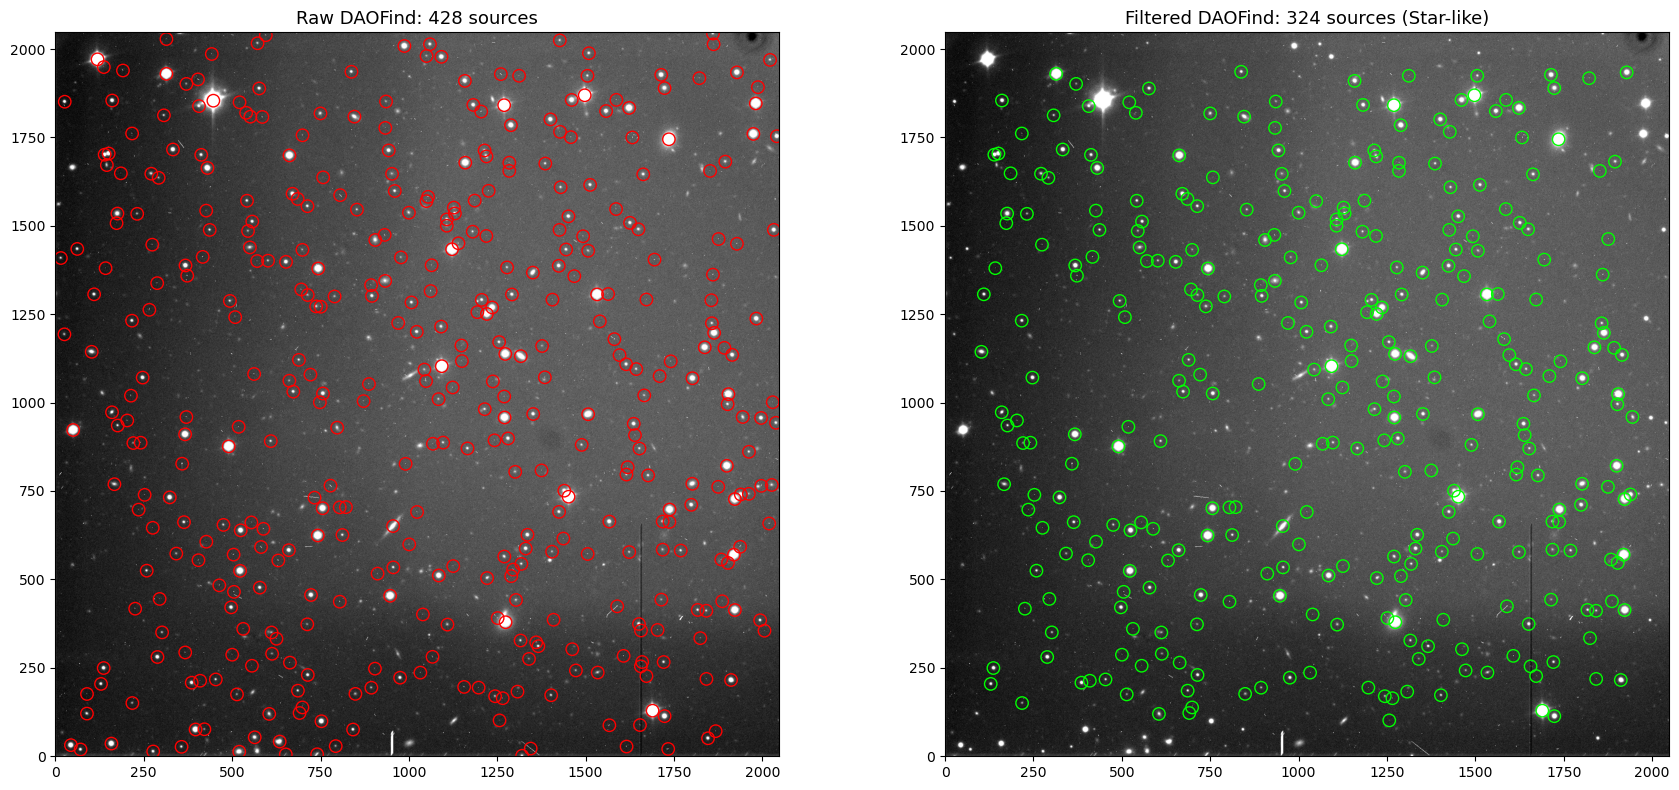

In [12]:
# ============================================================
# CELL 8: STEP 5 — DAOSTARFINDER + SHAPE FILTERING
# ============================================================

# CELL 8: STEP 3 - DAOSTARFINDER        
sources       = DAOStarFinder(fwhm=final_fwhm, threshold=DETECT_SIGMA * std_bg)(clean_data)
clean_sources = run_daofinder(clean_data, std_bg, final_fwhm)

plot_detection_map(data, sources, clean_sources, save=True)

In [13]:
# CELL 9: STEP 4 - MULTI-APERTURE PHOTOMETRY
master_phot_table, error_array = run_multi_aperture_photometry(clean_data, clean_sources, final_fwhm, std_bg)

print("\n=== Master Photometry Table (first 5 rows) ===")
flux_cols = ['id'] + [f'flux_{m}x' for m in APERTURE_MULTIPLIERS]
print(master_phot_table[flux_cols][:5])

[Photometry] Multi-aperture complete. Evaluated 6 sizes.

=== Master Photometry Table (first 5 rows) ===
 id flux_1.25x flux_1.5x  flux_1.75x flux_2.0x  flux_2.5x  flux_3.0x 
--- ---------- ---------- ---------- ---------- ---------- ----------
 24     103.68      62.04      10.94     -54.81    -149.70    -141.38
 25   49184.04   51687.00   53158.03   54044.95   54881.72   55034.49
 26    4085.26    4708.47    5182.79    5523.10    5979.78    6180.83
 28     321.25     317.88     287.60     303.85     278.16     308.45
 29 1594478.96 1681051.11 1733213.31 1766072.40 1800703.78 1812687.24


[Astrometry] Target expected at X=1102.61, Y=889.00
[Astrometry] ✅ Target matched at 1.14

--- QUICK LOOK VERDICT ---
✅ GRB200412 DETECTED at 1.14
   Centroid: X=1097.0, Y=887.0
   Instrumental mag (1.5×FWHM aperture): -8.064
[Recenter] 🎯 Shifted target to local peak: X=1097.0, Y=886.9 (RA: 278.31402, Dec: 62.53241) - Shift: 6.00px
[Plot] Saved → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/target/GRB200412_confirmation.png


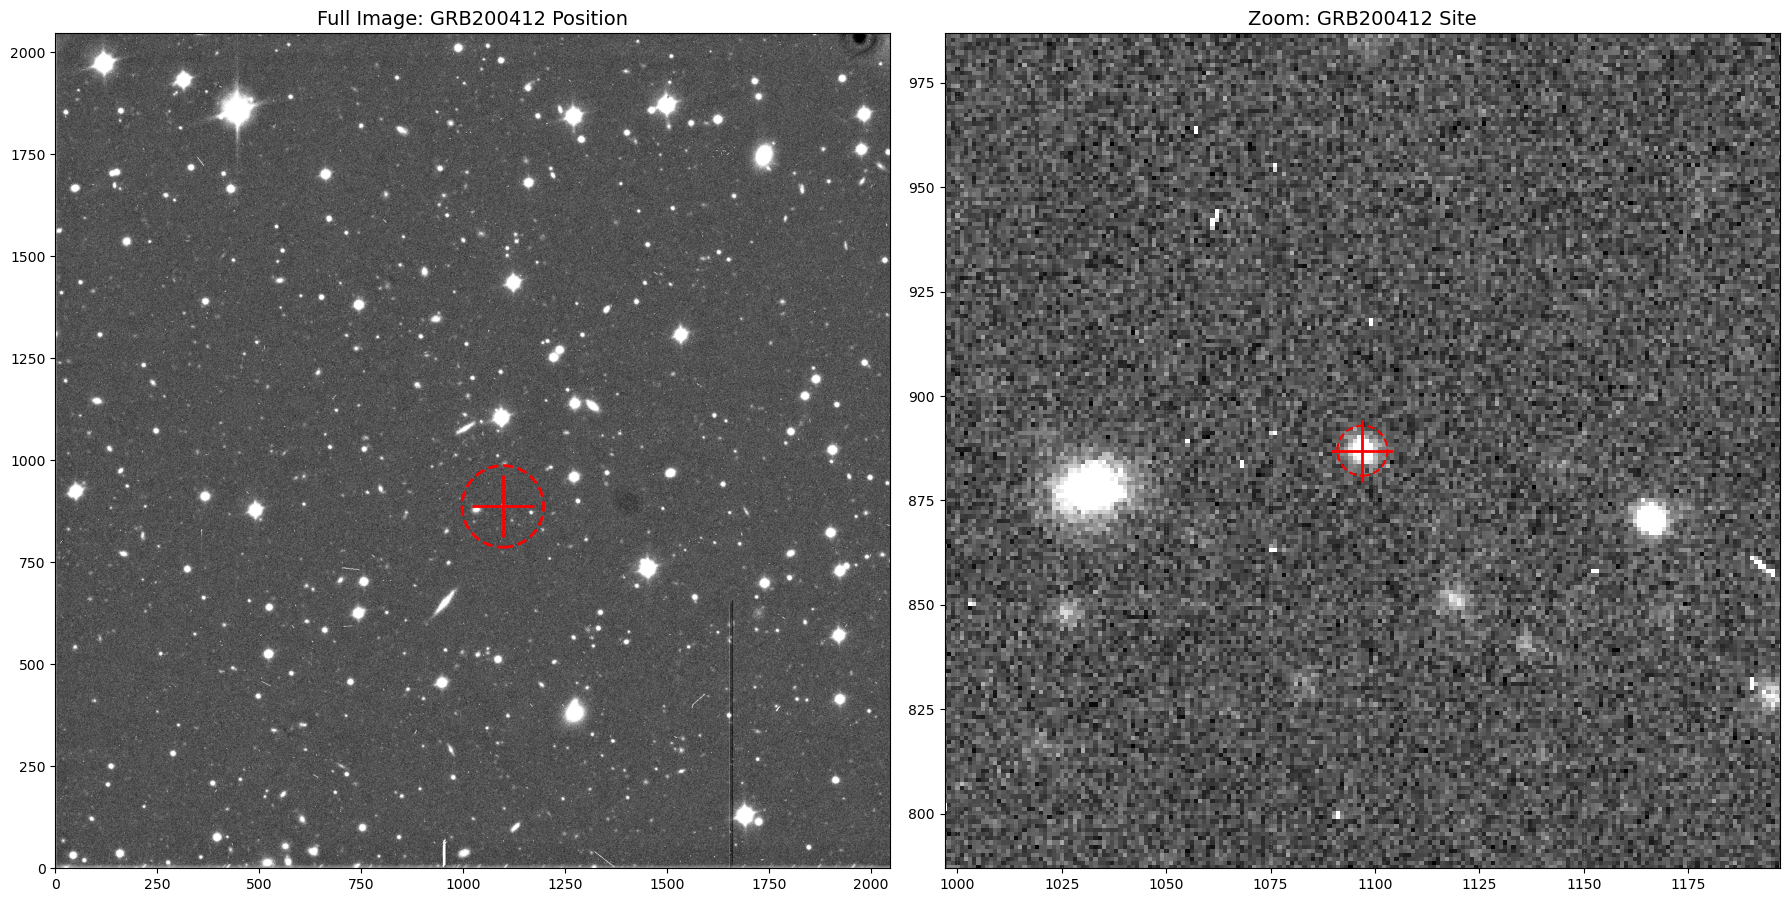

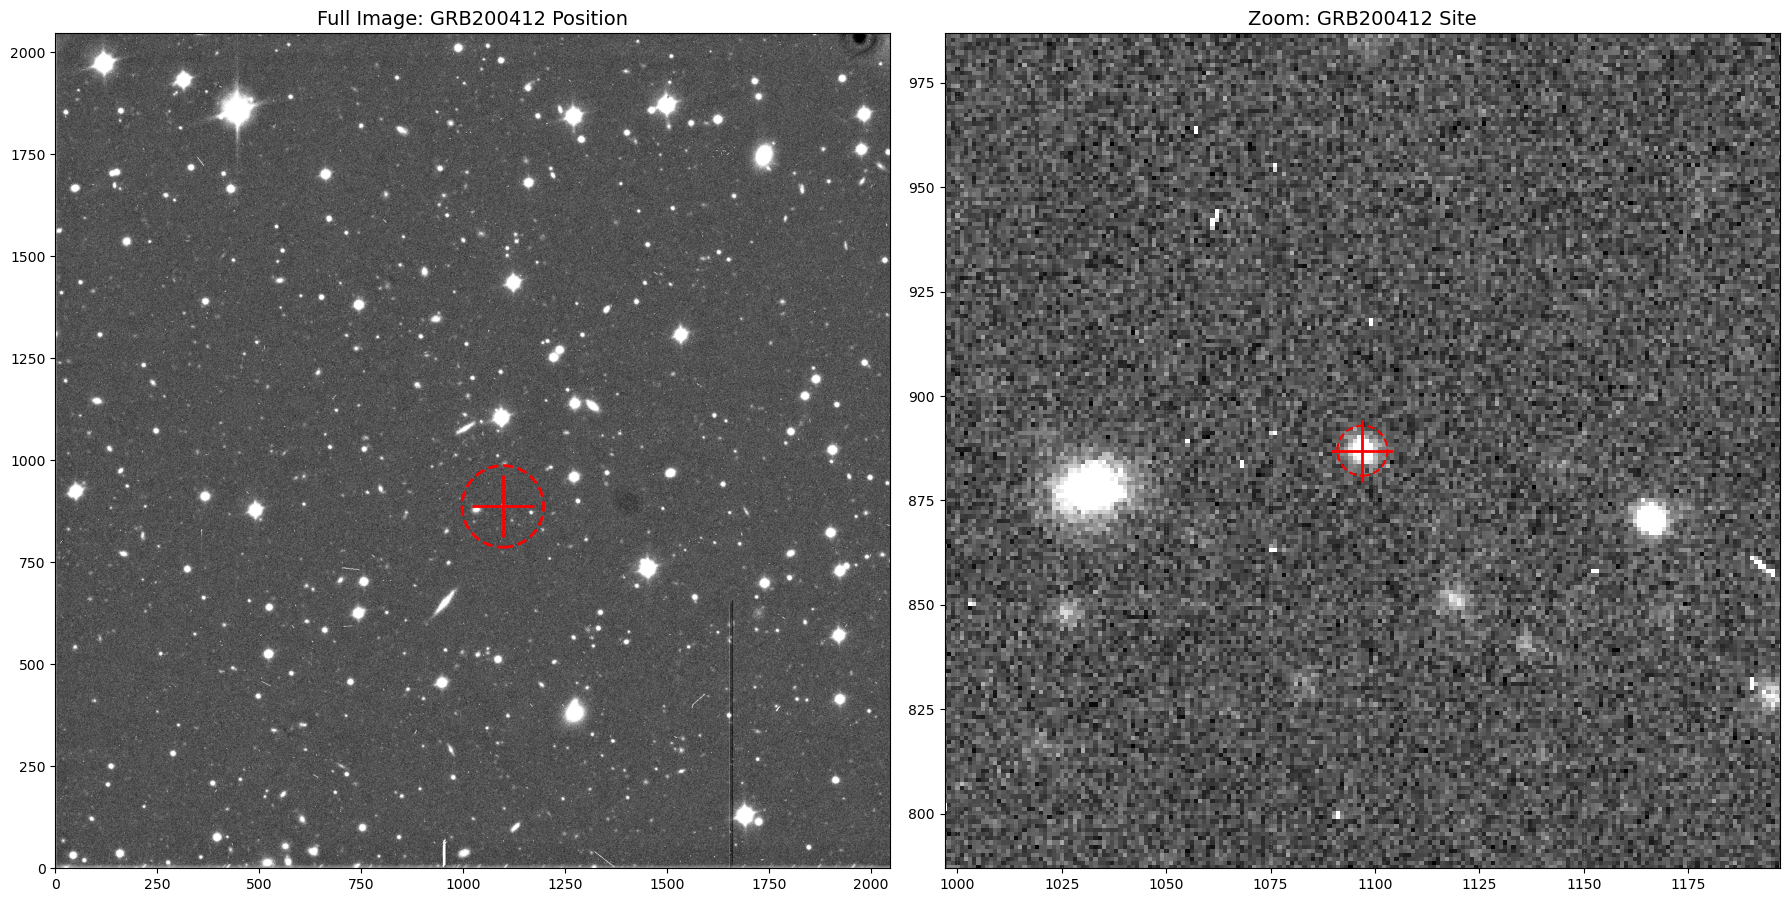

In [14]:
# ============================================================
# CELL 10: STEP 7 — ASTROMETRY & GRB MATCH VERDICT
# ============================================================

catalog_coords, grb_pixel_x, grb_pixel_y, match_idx, match_dist_arcsec, detected = \
    match_target_to_catalog(wcs, master_phot_table, TARGET_RA, TARGET_DEC)

print("\n--- QUICK LOOK VERDICT ---")
if detected:
    grb_row = master_phot_table[match_idx]
    flux_opt = grb_row[f'flux_{OPTIMAL_APERTURE}x']
    if flux_opt > 0:
        m_inst = -2.5 * np.log10(flux_opt)
        print(f"✅ {TARGET_NAME} DETECTED at {match_dist_arcsec:.2f}")
        print(f"   Centroid: X={grb_row['xcentroid']:.1f}, Y={grb_row['ycentroid']:.1f}")
        print(f"   Instrumental mag ({OPTIMAL_APERTURE}×FWHM aperture): {float(m_inst):.3f}")
    else:
        print("⚠️  Source detected but negative flux — check background subtraction.")
else:
    print(f"❌ {TARGET_NAME} NOT detected in this frame.")
    print(f"   Closest source: {match_dist_arcsec:.2f}" )
    print(f"   Expected at X={grb_pixel_x:.1f}, Y={grb_pixel_y:.1f}")

grb_pixel_x, grb_pixel_y = recenter_target_coordinates(clean_data, grb_pixel_x, grb_pixel_y, RECENTER_RADIUS_PIX, wcs)


plot_target_confirmation(clean_data, grb_pixel_x, grb_pixel_y, TARGET_NAME, save=True)

In [15]:
# ============================================================
# CELL 11: STEP 8 — PAN-STARRS ZERO-POINT CALIBRATION
# ============================================================

master_phot_table, master_zp, master_zp_err, good_stars, zp_idx, zp_d2d = \
    calibrate_zero_point(master_phot_table, wcs, clean_data, catalog_coords)

if np.isnan(master_zp):
    print("⚠️  Proceeding without calibrated magnitudes.")

[ZP] ✅ Master Zero Point = 30.119 ± 0.018  (from 8 stars)



--- Calibration Stars Cross-Check ---
Star   |        X |        Y |    PanSTARRS |     Pipeline |     Diff
-----------------------------------------------------------------
1      |   490.33 |   876.24 |       15.682 |       15.678 |   -0.004
2      |  1689.43 |   128.49 |       14.556 |       14.555 |   -0.001
3      |  1451.77 |   733.77 |       14.897 |       14.892 |   -0.005
4      |  1092.99 |  1102.99 |       15.160 |       15.161 |   +0.001
5      |   314.12 |  1930.04 |       15.317 |       15.322 |   +0.005
6      |  1269.53 |  1841.37 |       14.915 |       14.904 |   -0.011
7      |  1497.42 |  1869.45 |       14.470 |       14.520 |   +0.050
8      |  1122.08 |  1433.82 |       15.515 |       15.520 |   +0.005
[Plot] Saved → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/calibration/zp_calibration.png


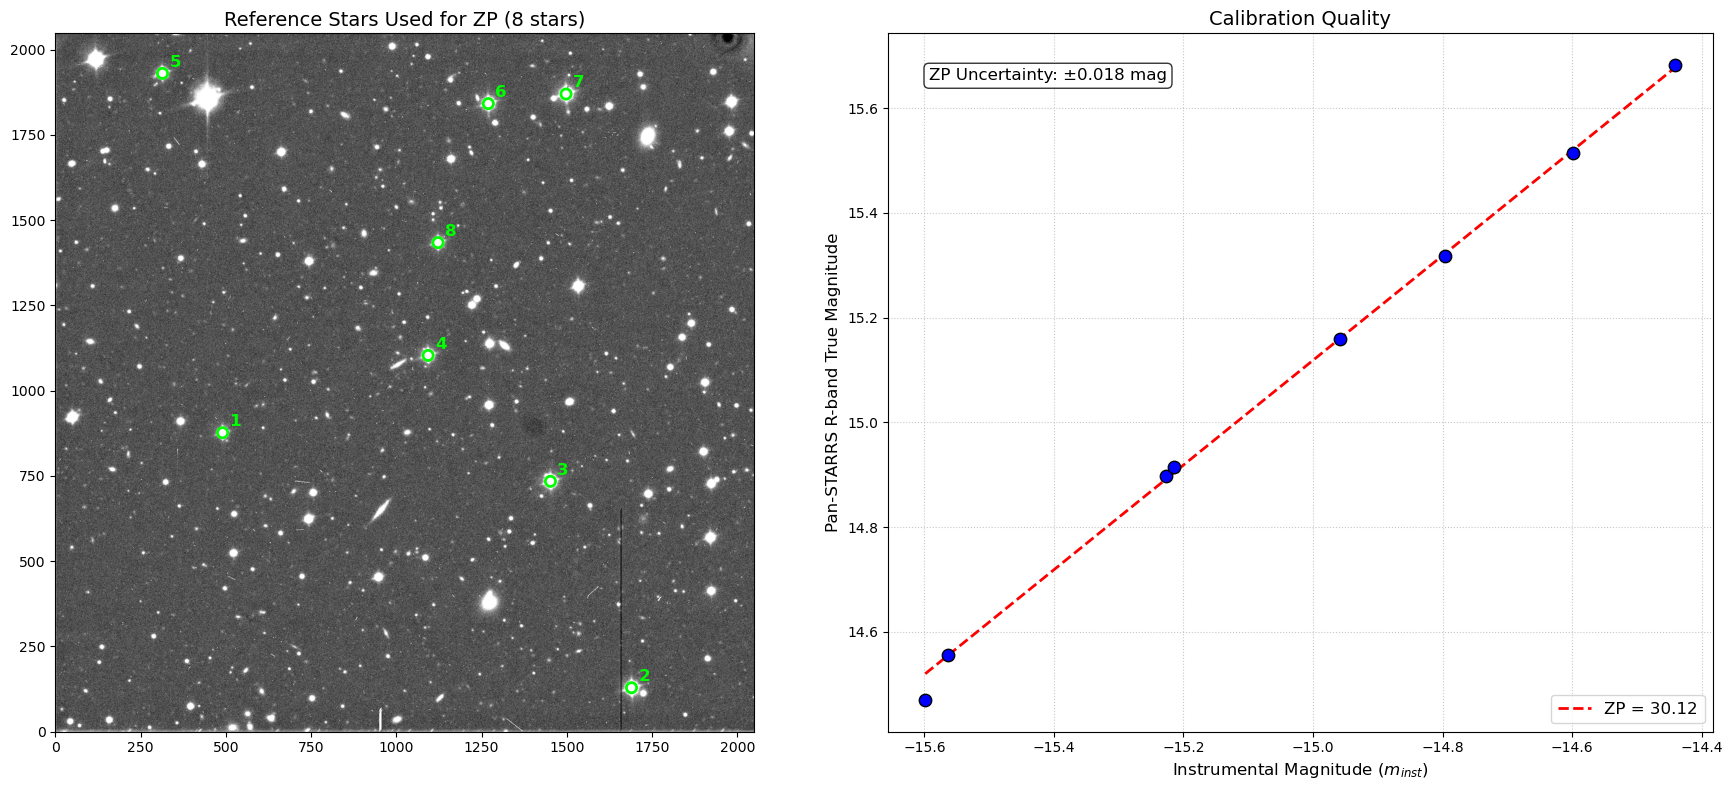

In [16]:
# ============================================================
# CELL 12: STEP 8.5 — CALIBRATION DIAGNOSTICS
# ============================================================

if not np.isnan(master_zp):
    plot_calibration_diagnostics(
        clean_data, master_phot_table, good_stars,
        zp_idx, zp_d2d, master_zp, master_zp_err, save=True
    )
else:
    print("Skipping calibration plot (no valid ZP).")

In [17]:
# ============================================================
# CELL 13: STEP 9 — FORCED PHOTOMETRY & UPPER LIMIT
# ============================================================

result = forced_photometry_upper_limit(
    clean_data, error_array,
    grb_pixel_x, grb_pixel_y,
    final_fwhm, master_zp, master_zp_err
)

print("\n" + "="*50)
print(f"  FINAL RESULT FOR {TARGET_NAME}")
print("="*50)
if result['detected']:
    print(f"  Magnitude : {result['magnitude']:.3f} ± {result['mag_err']:.3f}")
else:
    print(f"  Upper Limit : > {result['upper_limit']:.2f} mag  ({UPPER_LIMIT_SIGMA}σ)")
print("="*50)

# --- VALUES PART: FORCED DIAGNOSTICS ---
print("\n" + "-"*50)
print("  FORCED CURVE OF GROWTH (VALUES)")
print("-" * 50)
forced_cog = forced_curve_of_growth(clean_data, error_array, grb_pixel_x, grb_pixel_y, final_fwhm, master_zp, std_bg)
print(f"[Forced CoG] Multipliers : {forced_cog['multipliers']}")
print(f"[Forced CoG] Fluxes      : {[round(f,2) for f in forced_cog['fluxes']]}")
print(f"[Forced CoG] SNRs        : {[round(s,2) for s in forced_cog['snrs']]}")
print(f"[Forced CoG] Mags        : {[round(m,3) if str(m) != 'nan' else 'NaN' for m in forced_cog['mags']]}")

[Forced Phot] Flux=1682.80, 1σ Noise=104.32, 3.0σ Threshold=312.97
[Forced Phot] ✅ SURPRISE DETECTION! mag = 22.054 ± 0.070
[Forced Phot]    at X=1097.0, Y=886.9 (RA: 278.31402, Dec: 62.53241)

  FINAL RESULT FOR GRB200412
  Magnitude : 22.054 ± 0.070

--------------------------------------------------
  FORCED CURVE OF GROWTH (VALUES)
--------------------------------------------------
[Forced CoG] Multipliers : [1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
[Forced CoG] Fluxes      : [1590.55, 1682.8, 1706.16, 1701.09, 1743.1, 1740.67]
[Forced CoG] SNRs        : [18.2, 16.13, 14.07, 12.3, 10.11, 8.43]
[Forced CoG] Mags        : [np.float64(22.115), np.float64(22.054), np.float64(22.039), np.float64(22.042), np.float64(22.015), np.float64(22.017)]



Step 10.5: Generating Aperture Diagnostic Plots...
✅ Using Forced Curve of Growth for the Diagnostic Plot (Values from Step 9).
[Plot] Saved Aperture Diagnostic → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/target/GRB200412_aperture_diagnostic.png


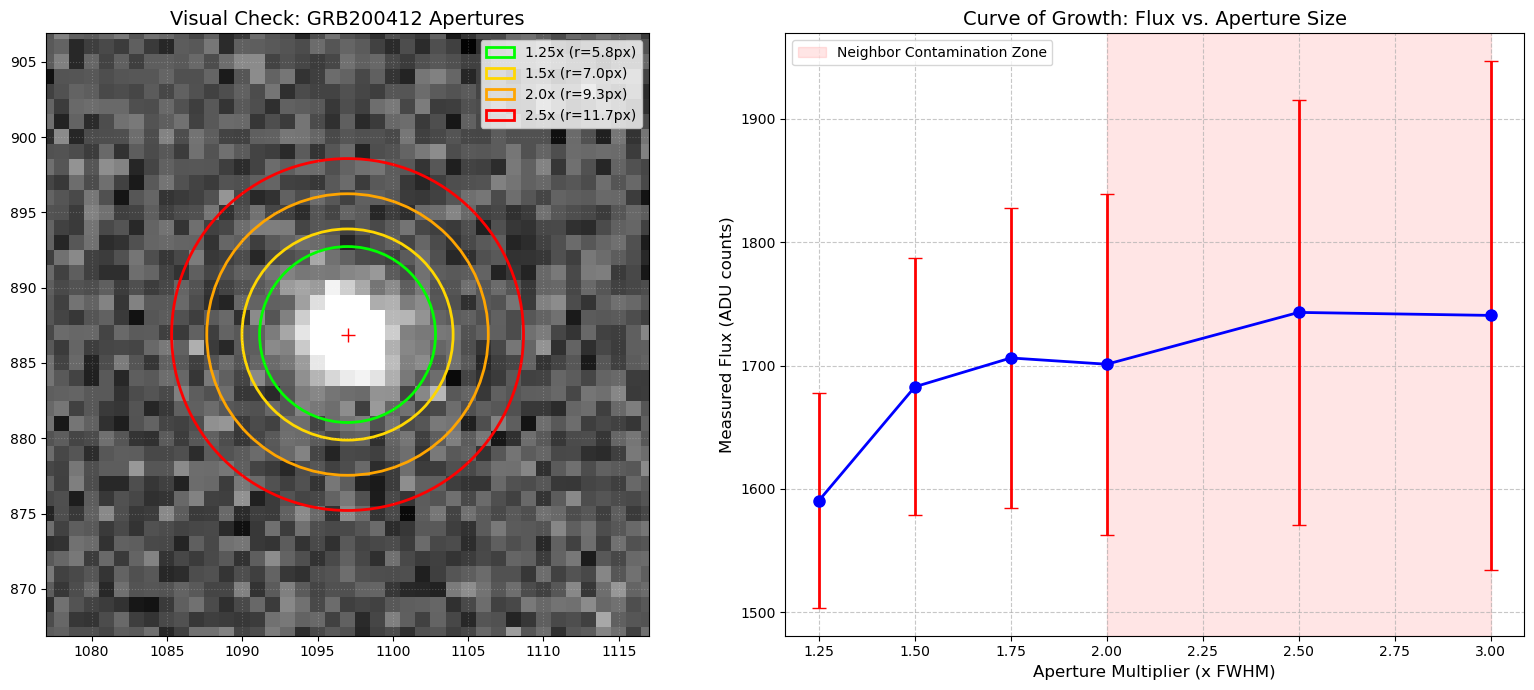

In [18]:
# ============================================================
# CELL 10.5: OPTIMAL APERTURE DIAGNOSTIC (CURVE OF GROWTH)
# ============================================================
print("\nStep 10.5: Generating Aperture Diagnostic Plots...")

if 'forced_cog' in locals():
    print("✅ Using Forced Curve of Growth for the Diagnostic Plot (Values from Step 9).")
    plot_aperture_diagnostic(
        clean_data=clean_data, 
        grb_pixel_x=grb_pixel_x, 
        grb_pixel_y=grb_pixel_y, 
        final_fwhm=final_fwhm, 
        target_name=TARGET_NAME, 
        forced_cog=forced_cog,
        save=True
    )
elif detected:
    print("⚠️ Forced CoG not found. Falling back to catalog detection row.")
    plot_aperture_diagnostic(
        clean_data=clean_data, 
        grb_pixel_x=grb_pixel_x, 
        grb_pixel_y=grb_pixel_y, 
        final_fwhm=final_fwhm, 
        target_name=TARGET_NAME, 
        grb_row=grb_row,
        save=True
    )
else:
    print("⚠️ Cannot run Aperture Diagnostic: Target was not detected and Forced CoG is missing.")


Step 6.5: Running Advanced PSF Photometry...
[PSF Phot] Initializing models (FWHM=4.67)...
[PSF Phot] Fitting grouped models. This may take a moment...


[Plot] Saved PSF Residuals → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/detection/GRB200412_psf_residuals.png


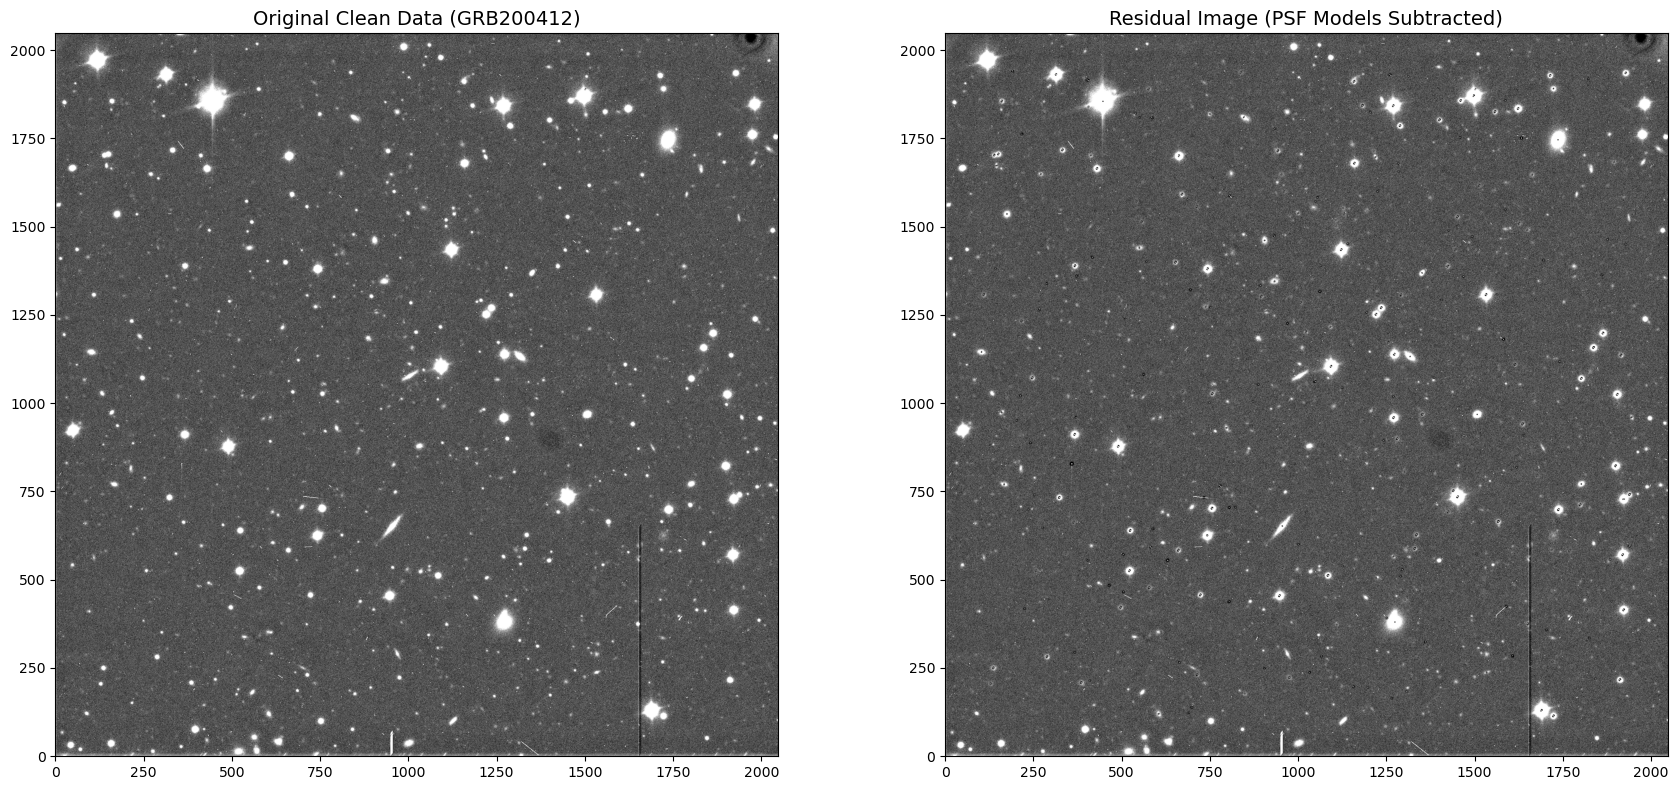


=== Top 10 PSF Photometry Results ===
 id group_id group_size  x_fit    y_fit    flux_fit 
--- -------- ---------- -------- ------- -----------
  1        1          1 1256.551 101.085     222.145
  2        2          1 1723.405 112.994   47834.715
  3        3          1  604.960 119.240    2727.102
  4        4          1  690.809 121.775     546.674
  5        5          1 1689.422 128.476 1541510.714
  6        6          1  698.818 137.580     726.287
  7        7          1  217.709 150.122    1376.191
  8        8          1 1265.527 163.485     583.618
  9        9          1 1243.867 169.366    1422.877
 10       10          1 1402.432 172.202    1944.551

Step 6.5b: Running Forced PSF Photometry (Matched Filter)...
[Forced PSF] Fitted flux = 1545.41 ± 67.39
[Forced PSF] 3.0σ threshold = 202.18
[Forced PSF] ✅ DETECTION: 22.146 ± 0.051 mag

Generating Forced PSF Profile diagnostic plot...
[Plot] Saved PSF Profile → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plo

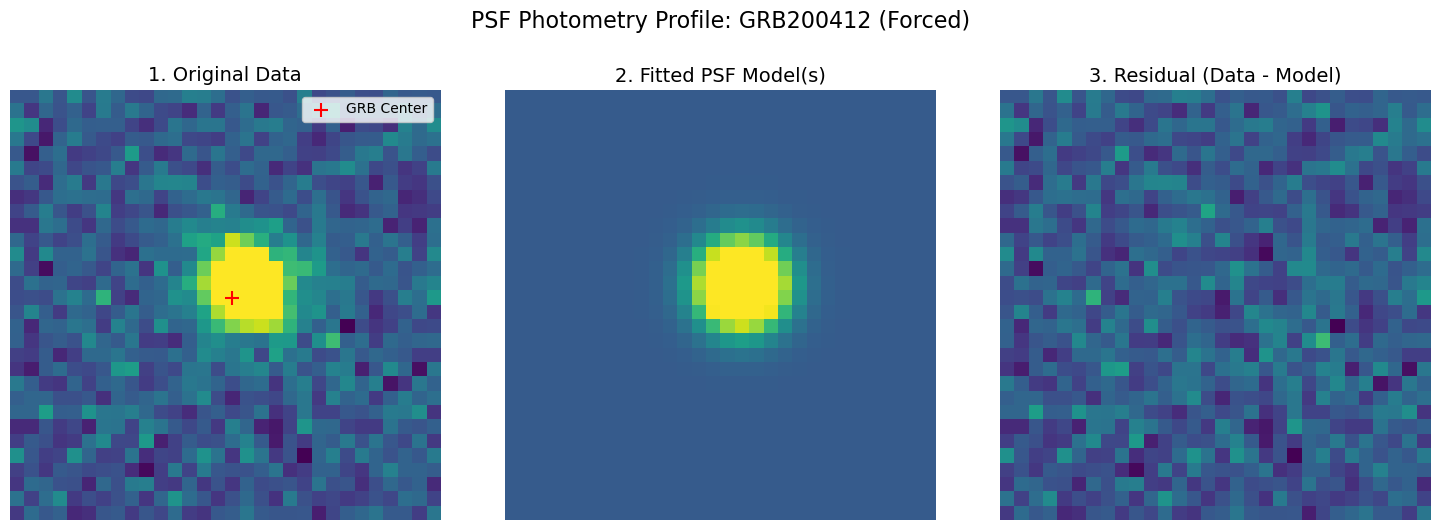

In [19]:
# ============================================================
# CELL 10.8: STEP 6.5 — ADVANCED PSF PHOTOMETRY
# ============================================================
print("\nStep 6.5: Running Advanced PSF Photometry...")

# Run the pipeline function we just created
psf_phot_table, resid_image = run_psf_photometry(
    data=clean_data, 
    error_array=error_array, 
    final_fwhm=final_fwhm, 
    std_bg=std_bg, 
    target_name=TARGET_NAME,
    save=True
)

print("\n=== Top 10 PSF Photometry Results ===")
print(psf_phot_table[('id', 'group_id', 'group_size', 'x_fit', 'y_fit', 'flux_fit')][:10])

# --- NEW: Forced PSF Photometry ---
print("\nStep 6.5b: Running Forced PSF Photometry (Matched Filter)...")
forced_psf_result = run_forced_psf_photometry(clean_data, error_array, grb_pixel_x, grb_pixel_y, final_fwhm, master_zp, master_zp_err, std_bg)

if 'resid_image' in forced_psf_result:
    print("\nGenerating Forced PSF Profile diagnostic plot...")
    plot_grb_psf(
        clean_data=clean_data, 
        resid_image=forced_psf_result['resid_image'], 
        grb_x=grb_pixel_x, 
        grb_y=grb_pixel_y, 
        target_name=TARGET_NAME + " (Forced)", 
        box_size=30,
        save=True
    )


Step 10: Extracting Final GRB Magnitude from PSF Models...
✅ GRB successfully isolated and measured via PSF Photometry!
   at X=1097.0, Y=886.9 (RA: 278.31402, Dec: 62.53241)
--------------------------------------------------
Target        : GRB200412
Match Distance: 0.01 pixels
Group Size    : 1 (If >1, it successfully deblended!)
Raw PSF Flux  : 1544.99 counts
Zero Point    : 30.119 ± 0.018
FINAL MAG     : 22.146 ± 0.051 mag
--------------------------------------------------

Generating PSF Profile diagnostic plot...
[Plot] Saved PSF Profile → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/plots/target/GRB200412_PSF_profile.png


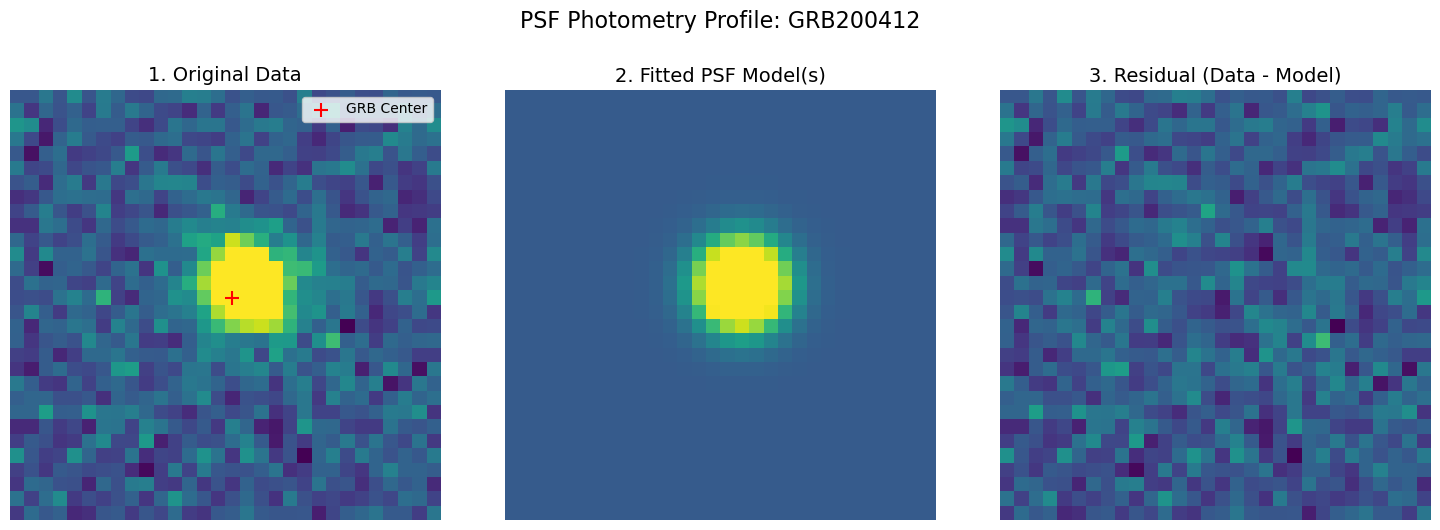


  FINAL FORCED PSF PHOTOMETRY RESULTS
  Magnitude : 22.146 ± 0.051 mag


In [20]:
# ============================================================
# CELL 15: FINAL PSF MAGNITUDE EXTRACTION
# ============================================================
print("\nStep 10: Extracting Final GRB Magnitude from PSF Models...")

if detected and not np.isnan(master_zp):
    
    # Call the extraction function (F14)
    psf_result = extract_psf_magnitude(
        psf_phot_table=psf_phot_table, 
        grb_pixel_x=grb_pixel_x, 
        grb_pixel_y=grb_pixel_y, 
        master_zp=master_zp, 
        master_zp_err=master_zp_err, 
        target_name=TARGET_NAME
    )
    
    # NEW: Plot the PSF if the extraction was successful
    if psf_result['detected']:
        print("\nGenerating PSF Profile diagnostic plot...")
        plot_grb_psf(
            clean_data=clean_data, 
            resid_image=resid_image, 
            grb_x=grb_pixel_x, 
            grb_y=grb_pixel_y, 
            target_name=TARGET_NAME, 
            box_size=30,      # A 30x30 pixel box is perfect for a 5px FWHM
            save=True
        )
    
else:
    print("Cannot extract PSF magnitude: Target not detected or Zero Point failed.")

# --- NEW: Forced PSF Photometry Values ---
print("\n" + "="*50)
print("  FINAL FORCED PSF PHOTOMETRY RESULTS")
print("="*50)
if 'forced_psf_result' in locals():
    if forced_psf_result['detected']:
        print(f"  Magnitude : {forced_psf_result['magnitude']:.3f} ± {forced_psf_result['mag_err']:.3f} mag")
    else:
        print(f"  Upper Limit : > {forced_psf_result['upper_limit']:.2f} mag ({UPPER_LIMIT_SIGMA}σ)")
else:
    print("  Forced PSF Photometry was not run.")
print("="*50)

In [21]:
from openpyxl.packaging import relationship
from openpyxl.packaging import relationship
from openpyxl.packaging import relationship
from openpyxl.packaging import relationship
from openpyxl.packaging import relationship
# ============================================================
# FINAL CELL: SAVE ALL OUTPUTS & DETAILED LOG
# ============================================================
# Saves: cleaned FITS, master photometry catalog, and a comprehensive summary log.

# --- 1. Save background-subtracted FITS ---
clean_fits_path = os.path.join(DIRS['fits_reduced'], f"clean_{os.path.basename(solved_path)}")
hdu = fits.PrimaryHDU(data=clean_data, header=header)
hdu.header['HISTORY'] = 'Background subtracted by photometry_pipeline.ipynb'
hdu.writeto(clean_fits_path, overwrite=True)
print(f"[Save] Clean FITS → {clean_fits_path}")

# --- 2. Save master photometry catalog as FITS & CSV ---
cat_path = os.path.join(DIRS['catalogs'], f"{TARGET_NAME}_photometry.fit")
csv_path = cat_path.replace('.fit', '.csv')
master_phot_table.write(cat_path, overwrite=True)
master_phot_table.write(csv_path, format='csv', overwrite=True)
print(f"[Save] Aperture Catalog (CSV) → {csv_path}")

# --- 2.5 Save Advanced PSF catalog if it exists ---
if 'psf_phot_table' in locals():
    psf_cat_path = os.path.join(DIRS['catalogs'], f"{TARGET_NAME}_psf_photometry.csv")
    psf_phot_table.write(psf_cat_path, format='csv', overwrite=True)
    print(f"[Save] PSF Catalog (CSV) → {psf_cat_path}")

# --- 3. WRITE THE COMPREHENSIVE PIPELINE LOG ---
log_path = os.path.join(DIRS['logs'], f"{TARGET_NAME}_pipeline.log")

import datetime
timestamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

with open(log_path, 'a') as f:
    # Header
    f.write("==================================================\n")
    f.write(f" PIPELINE RUN: {TARGET_NAME} @ {timestamp}\n")
    f.write("==================================================\n")
    f.write(f"Run Mode    : {RUN_MODE.upper()}\n")
    f.write(f"Input file  : {FINAL_IMAGE_TO_PROCESS}\n")
    f.write(f"Calibration : {CALIBRATION_SYSTEM} ({VIZIER_CATALOG_ID})\n")
    # --- Time Extraction ---
    from astropy.time import Time
    orig_header = fits.getheader(FINAL_IMAGE_TO_PROCESS)
    date_obs_str = orig_header.get('DATE-OBS', 'UNKNOWN')
    t_obs_jd = np.nan
    delta_t_days = np.nan
    if date_obs_str != 'UNKNOWN':
        date_obs_clean = date_obs_str.replace('"T"', 'T')
        try:
            t_obs = Time(date_obs_clean, format='isot', scale='utc')
            t_obs_jd = t_obs.jd
            delta_t_days = t_obs_jd - GRB_T0_JD
        except Exception as e:
            print(f"⚠️ Could not parse DATE-OBS: {e}")
            pass

    f.write(f"DATE-OBS    : {date_obs_str}\n")
    f.write(f"Obs JD      : {t_obs_jd:.4f}\n")
    f.write(f"T - T_0     : {delta_t_days:.4f} days\n\n")
    f.write(f"Solved FITS : {solved_path}\n")
    if 'wcs' in locals() and wcs is not None:
        pixel_scale_degrees = wcs.proj_plane_pixel_scales()[0].value
        pixel_scale_arcsec = pixel_scale_degrees * 3600
        f.write(f"Pixel Scale : {pixel_scale_arcsec:.3f} arcsec/pix\n")
    f.write(f"GRB Target  : RA={TARGET_RA}, Dec={TARGET_DEC}\n")
    
    if 'wcs' in locals() and wcs is not None and 'grb_pixel_x' in locals():
        recentered_ra, recentered_dec = wcs.pixel_to_world_values(grb_pixel_x, grb_pixel_y)
        f.write(f"Recentered  : RA={float(recentered_ra):.5f}, Dec={float(recentered_dec):.5f} (X={grb_pixel_x:.1f}, Y={grb_pixel_y:.1f})\n")
    f.write("\n")

    # Image Quality Summary
    f.write("--- IMAGE QUALITY SUMMARY ---\n")
    f.write(f"FWHM        : {final_fwhm:.2f} px\n")
    f.write(f"Sky mean    : {mean_bg:.2f}\n")
    f.write(f"Sky std     : {std_bg:.2f}\n")
    f.write(f"Num sources : {len(master_phot_table)}\n\n")

    # Calibration Results & Cross-Check Table
    f.write("--- ZERO POINT CALIBRATION ---\n")
    f.write(f"Zero Point  : {master_zp:.3f} ± {master_zp_err:.3f}\n")
    
    # Reconstruct the Pan-STARRS match table
    if 'good_stars' in locals() and 'zp_idx' in locals():
        f.write("\nCalibration Stars Cross-Check:\n")
        f.write(f"{'Star':<6} | {'PanSTARRS (True)':<20} | {'Pipeline':<10} | {'Diff':<10}\n")
        f.write("-" * 60 + "\n")
        
        valid_count = 1
        for i in range(len(good_stars)):
            if zp_d2d[i].arcsec < ZP_MATCH_RADIUS_AS:
                inst_mag = master_phot_table['m_inst'][zp_idx[i]]
                if not np.isnan(inst_mag):
                    true_mag = good_stars['true_mag'][i]
                    calib_mag = inst_mag + master_zp
                    diff = calib_mag - true_mag
                    f.write(f"{valid_count:<6} | {true_mag:<20.3f} | {calib_mag:<10.3f} | {diff:+.3f}\n")
                    valid_count += 1
    f.write("\n")

    # Forced Photometry Results
    f.write("--- FORCED APERTURE PHOTOMETRY ---\n")
    f.write(f"Aperture    : {OPTIMAL_APERTURE}x FWHM\n")
    if result['detected']:
        f.write("Result      : DETECTED\n")
        f.write(f"FINAL MAG   : {result['magnitude']:.3f} ± {result['mag_err']:.3f} mag ({FILTER_BAND}-band)\n")
    else:
        f.write("Result      : NON-DETECTION\n")
        f.write(f"Upper Limit : > {result['upper_limit']:.2f} mag ({UPPER_LIMIT_SIGMA}σ)\n")
    f.write("\n")

    # Advanced PSF Photometry Results

    # NEW: Forced PSF and CoG Results
    f.write("--- FORCED PSF PHOTOMETRY ---\n")
    if 'forced_psf_result' in locals():
        if forced_psf_result['detected']:
            f.write("Result      : DETECTED\n")
            f.write(f"FINAL MAG   : {forced_psf_result['magnitude']:.3f} ± {forced_psf_result['mag_err']:.3f} mag ({FILTER_BAND}-band)\n")
        else:
            f.write("Result      : NON-DETECTION\n")
            f.write(f"Upper Limit : > {forced_psf_result['upper_limit']:.2f} mag ({UPPER_LIMIT_SIGMA}σ)\n")
    else:
        f.write("Result      : FORCED PSF NOT RUN\n")
    f.write("\n")
    
    f.write("--- FORCED CURVE OF GROWTH ---\n")
    if 'forced_cog' in locals():
        f.write(f"Multipliers : {forced_cog['multipliers']}\n")
        snrs = [round(s,2) for s in forced_cog['snrs']]
        f.write(f"SNRs        : {snrs}\n")
    else:
        f.write("Result      : FORCED CoG NOT RUN\n")
    f.write("\n")
    f.write("--- ADVANCED PSF PHOTOMETRY ---\n")
    if 'psf_result' in locals():
        if psf_result['detected']:
            f.write("Result        : DETECTED (Target Isolated!)\n")
            f.write(f"Match Distance: {psf_result['match_dist']:.2f} pixels\n")
            f.write(f"Group Size    : {psf_result['group_size']} (If >1, it successfully deblended!)\n")
            f.write(f"Raw PSF Flux  : {psf_result['flux']:.2f} counts\n")
            f.write(f"FINAL MAG     : {psf_result['magnitude']:.3f} ± {psf_result['mag_err']:.3f} mag ({FILTER_BAND}-band)\n")
        else:
            f.write("Result      : TARGET NOT ISOLATED IN PSF MODELS\n")
    else:
        f.write("Result      : PSF PHOTOMETRY NOT RUN\n")
        
    f.write("==================================================\n")

print(f"[Save] Comprehensive Log → {log_path}")

print("\n✅ Pipeline complete! All outputs saved.")
print(f"   Output root: {OUTPUT_BASE_DIR}")

[Save] Clean FITS → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/fits/reduced/clean_online_solved_MASTER_STACKED_aaGRB_R.fits
[Save] Aperture Catalog (CSV) → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/catalogs/GRB200412_photometry.csv
[Save] PSF Catalog (CSV) → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/catalogs/GRB200412_psf_photometry.csv
[Save] Comprehensive Log → ./pipeline_output/MASTER_STACKED_aaGRB_R_stack_Pan-STARRS/logs/GRB200412_pipeline.log

✅ Pipeline complete! All outputs saved.
   Output root: ./pipeline_output


In [22]:
# Extract the pixel scale directly from WCS
# wcs.proj_plane_pixel_scales() returns the scale in degrees per pixel
pixel_scale_degrees = wcs.proj_plane_pixel_scales()[0].value

# Convert degrees to arcseconds (1 degree = 3600 arcseconds)
pixel_scale_arcsec = pixel_scale_degrees * 3600

print(f"Telescope's Pixel Scale: {pixel_scale_arcsec:.3f} arcseconds / pixel")

Telescope's Pixel Scale: 0.191 arcseconds / pixel


# 🤖 BATCH PROCESSING MODE
If you set `RUN_MODE = 'batch'` in CELL 2, this block will automatically run the entire pipeline loop across all files matching your `BATCH_PATTERN` and compile a master CSV summary of the GRB's photometry.

In [23]:
# ============================================================
# CELL 16: BATCH PROCESSING MODE
# ============================================================
import pandas as pd

if RUN_MODE == 'batch':
    print(f"🚀 Starting Batch Pipeline using pattern: {BATCH_PATTERN}")
    files_to_process = glob.glob(BATCH_PATTERN)
    
    if len(files_to_process) == 0:
        print("❌ No files found matching the batch pattern.")
    else:
        results = []
        for file in sorted(files_to_process):
            setup_output_dirs(file, RUN_MODE)
            print(f"\n" + "="*50)
            print(f"► Processing File: {file}")
            print("="*50)
            
            if PLATE_SOLVE_MODE == 'online':
                solved_path, data, header, wcs = run_online_plate_solve(file, TARGET_RA, TARGET_DEC)
            elif PLATE_SOLVE_MODE == 'copy':
                solved_path, data, header, wcs = run_copy_wcs_plate_solve(file, WCS_REFERENCE_FRAME)
            else:
                solved_path, data, header, wcs = run_local_plate_solve(file, ASTROMETRY_CFG, TARGET_RA, TARGET_DEC)
                
            if solved_path is None:
                print(f"⚠️ Skipping {file}: Plate solving failed.")
                continue
                
            clean_data, final_fwhm, background_rms, mean_bg, median_bg, std_bg, header = measure_image_fwhm(solved_path)
            # --- Time Extraction ---
            orig_header = fits.getheader(file)
            date_obs_str = orig_header.get('DATE-OBS', 'UNKNOWN')
            t_obs_jd = np.nan
            delta_t_days = np.nan
            if date_obs_str != 'UNKNOWN':
                date_obs_clean = date_obs_str.replace('"T"', 'T')
                try:
                    from astropy.time import Time
                    t_obs = Time(date_obs_clean, format='isot', scale='utc')
                    t_obs_jd = t_obs.jd
                    delta_t_days = t_obs_jd - GRB_T0_JD
                except:
                    pass
            if final_fwhm is None:
                print(f"⚠️ Skipping {file}: FWHM measurement failed.")
                continue
                
            clean_sources = run_daofinder(clean_data, std_bg, final_fwhm)
            master_phot_table, error_array = run_multi_aperture_photometry(clean_data, clean_sources, final_fwhm, std_bg)
            catalog_coords, grb_x, grb_y, idx, dist_arcsec, detected = match_target_to_catalog(wcs, master_phot_table, TARGET_RA, TARGET_DEC)
            grb_x, grb_y = recenter_target_coordinates(clean_data, grb_x, grb_y, RECENTER_RADIUS_PIX, wcs)

            master_phot_table, master_zp, master_zp_err, good_stars, zp_idx, zp_d2d = calibrate_zero_point(master_phot_table, wcs, clean_data, catalog_coords)
            phot_result = forced_photometry_upper_limit(clean_data, error_array, grb_x, grb_y, final_fwhm, master_zp, master_zp_err, wcs)

            
            
            # --- NEW: Forced Diagnostics ---
            forced_cog = forced_curve_of_growth(clean_data, error_array, grb_x, grb_y, final_fwhm, master_zp, std_bg)
            forced_psf_result = run_forced_psf_photometry(clean_data, error_array, grb_x, grb_y, final_fwhm, master_zp, master_zp_err, std_bg)
            
            results.append({
                'filename': file,
                'fwhm_px': round(final_fwhm, 2),
                'zero_point': master_zp,
                'detected': phot_result['detected'],
                'target_mag': phot_result.get('magnitude', np.nan),
                'target_mag_err': phot_result.get('mag_err', np.nan),
                'upper_limit': phot_result.get('upper_limit', np.nan)
            })
            
        if len(results) > 0:
            df = pd.DataFrame(results)
            out_csv = os.path.join(OUTPUT_BASE_DIR, f"batch_summary_{FILTER_BAND}_{CALIBRATION_SYSTEM}.csv")
            df.to_csv(out_csv, index=False)
            print(f"\n✅ Batch Processing Complete! Summary saved to {out_csv}")
else:
    print("Skipping batch mode. Change RUN_MODE = 'batch' in CELL 2 to execute this.")


Skipping batch mode. Change RUN_MODE = 'batch' in CELL 2 to execute this.
